In [1]:
import sys
sys.path.append("/hlabhome/wg-mjames/git/Toby_work")
import pandas as pd
import numpy as np
import elephant
from scipy import stats,signal,integrate
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn import metrics, preprocessing
from sklearn.feature_selection import RFE
import imblearn
from imblearn import over_sampling
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import ks_2samp
import pickle
import random
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from graphical_functions import *
from helper_functions_math_addons import *
from helper_functions_file_handling import *
from helper_functions_modeling import *
from sklearn.utils.class_weight import compute_sample_weight
%load_ext autoreload
%autoreload 2
import os
NCPU = "4"
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['OPENBLAS_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
os.environ['VECLIB_MAXIMUM_THREADS'] = '4'
os.environ['NUMEXPR_NUM_THREADS'] = '4'
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.family':'DejaVu Sans'})

In [2]:
split_thres = (0.6, 0.8)
addon = 'unfiltered'
downlims = [10,4,10]
load_data = True

train_scaled, test_scaled = obtain_train_test_scaled_data(split_thres, addon, load_data, downlims)

Loaded successfully


In [79]:
split_thres = (0.4, 0.6)
addon = 'downisiset'
downlims = [10,4,10]
load_data = True

down_train_scaled, down_test_scaled = obtain_train_test_scaled_data(split_thres, addon, load_data, downlims)

Loaded successfully


In [4]:
graphic_train = get_extended_condensed_data(train_scaled)
models = train_multi_models(train_scaled, sampling_types=['over'], methods=['LogReg'])
cms = get_cms_multi(test_scaled, models, get_spiking=True, include_timing=False)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4316/4316 [00:14<00:00, 295.14it/s]


In [80]:
down_graphic_train = get_extended_condensed_data(down_train_scaled)
down_models = train_multi_models(down_train_scaled, sampling_types=['over'], methods=['LogReg'])


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2808/2808 [00:19<00:00, 141.39it/s]


In [84]:
down_cms = get_cms_multi(down_test_scaled, down_models, get_spiking=True, include_timing=False)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2808/2808 [00:09<00:00, 301.46it/s]


In [5]:
acc_break, labs, right_v_wrong = accuracy_breakdown(graphic_train, cms['LogReg_over'],
                                                   by_geno=True, by_age=True)

zbr106_101_0223_0_12_28_wt don't have a model :(


Datapoints per: 98385, 31207
Datapoints per: 99688, 50095
Datapoints per: 101244, 31498
Datapoints per: 68011, 57288


Text(0.5, 1.0, 'Confidence Spreads by Genotype/Age Grouping Unfiltered')

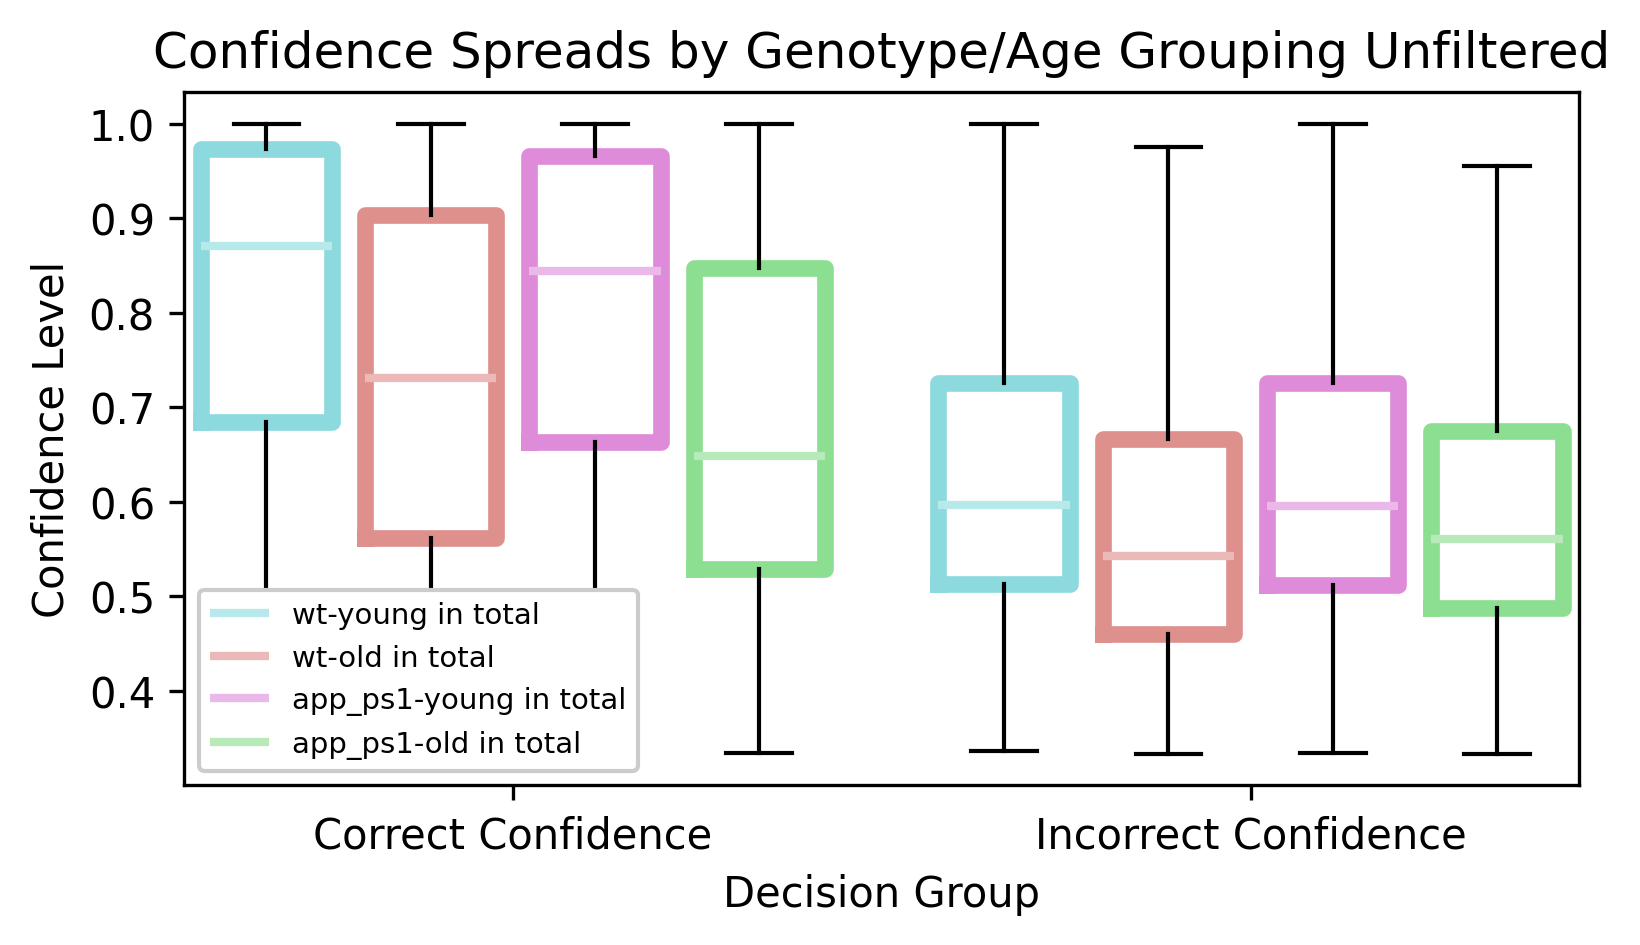

In [6]:
fig,ax = plt.subplots(1,1, figsize=(6,3), dpi=300)
plots, poses = box_whisker(*[(i[0], i[2]) for i in acc_break], showfliers=False,
           color_by_group=False, labels = ['Correct Confidence', "Incorrect Confidence"],
                          box_linewidth=4, ax=ax)
plt.legend([boxplot['medians'][0] for boxplot in plots],labs, loc='lower left', framealpha=1, fontsize=7)
plt.ylabel("Confidence Level")
plt.xlabel("Decision Group")
plt.title("Confidence Spreads by Genotype/Age Grouping Unfiltered")

In [113]:
for i in range(3):
    print(labs[i])
    print(ttest_ind(acc_break[0][i], acc_break[0][-1], equal_var=False, alternative='less'))

wt-young in total
TtestResult(statistic=np.float64(623.7997689143508), pvalue=np.float64(1.0), df=np.float64(74729.81619830953))
wt-old in total
TtestResult(statistic=np.float64(-62.756242919450884), pvalue=np.float64(0.0), df=np.float64(61234.96087310626))
app_ps1-young in total
TtestResult(statistic=np.float64(473.1076347483069), pvalue=np.float64(1.0), df=np.float64(63308.73486060909))


In [114]:
for i in range(len(acc_break)):
    print(labs[i])
    print(ttest_ind(acc_break[i][0], acc_break[i][2], equal_var=False, alternative='greater'))

wt-young in total
TtestResult(statistic=np.float64(59.187850339118924), pvalue=np.float64(0.0), df=np.float64(65115.85450178024))
wt-old in total
TtestResult(statistic=np.float64(80.55106092488829), pvalue=np.float64(0.0), df=np.float64(171578.3817559712))
app_ps1-young in total
TtestResult(statistic=np.float64(48.81514700401659), pvalue=np.float64(0.0), df=np.float64(86525.41707249165))
app_ps1-old in total
TtestResult(statistic=np.float64(17.47579519614264), pvalue=np.float64(1.9276185009040215e-68), df=np.float64(41321.63475433867))


In [8]:
use = []
for i, label in enumerate(labs):
    look = order_by_conf_right(acc_break[i], right_v_wrong[i])
    #print(label)
    #display(look)
    use.append(look)

In [93]:
use[0]

,right_conf,wrong_conf,bystander_conf,corr_state,wrong_guess_state,close_ratio
0,0.336889,3.281554e-01,3.349554e-01,0,2,5.773485e-03
1,0.340675,3.275374e-01,3.317877e-01,1,0,2.678562e-02
2,0.342108,3.391805e-01,3.187116e-01,2,1,7.340889e-02
3,0.344369,3.147621e-01,3.408688e-01,2,1,1.026864e-02
4,0.347537,3.365099e-01,3.159529e-01,0,2,9.996541e-02
...,...,...,...,...,...,...
49186,1.000000,1.005423e-15,1.110223e-16,1,0,9.007199e+15
49187,1.000000,8.769394e-27,8.881784e-16,2,1,1.125900e+15
49188,1.000000,3.445574e-20,6.661338e-16,2,1,1.501200e+15
49189,1.000000,6.736646e-29,2.220446e-16,2,1,4.503600e+15


Datapoints per: 98320, 98320, 98320
Datapoints per: 99671, 99671, 99671
Datapoints per: 101217, 101217, 101217
Datapoints per: 67954, 67954, 67954


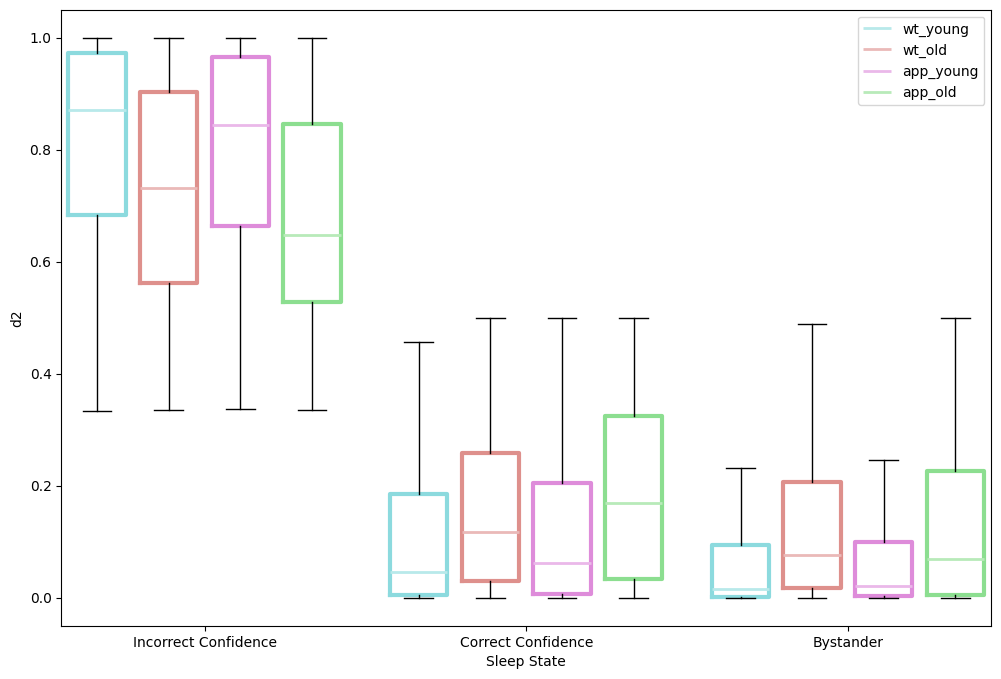

In [9]:
plots, poses = box_whisker(*[(i.right_conf, i.wrong_conf, i.bystander_conf) for i in use], inner_d2=False, showfliers=False,
           color_by_group=False, labels = ['Incorrect Confidence', "Correct Confidence", "Bystander"])
plt.legend([boxplot['medians'][0] for boxplot in plots],['wt_young', 'wt_old','app_young', 'app_old'])

zbr106_101_0223_0_12_28_wt don't have a model :(


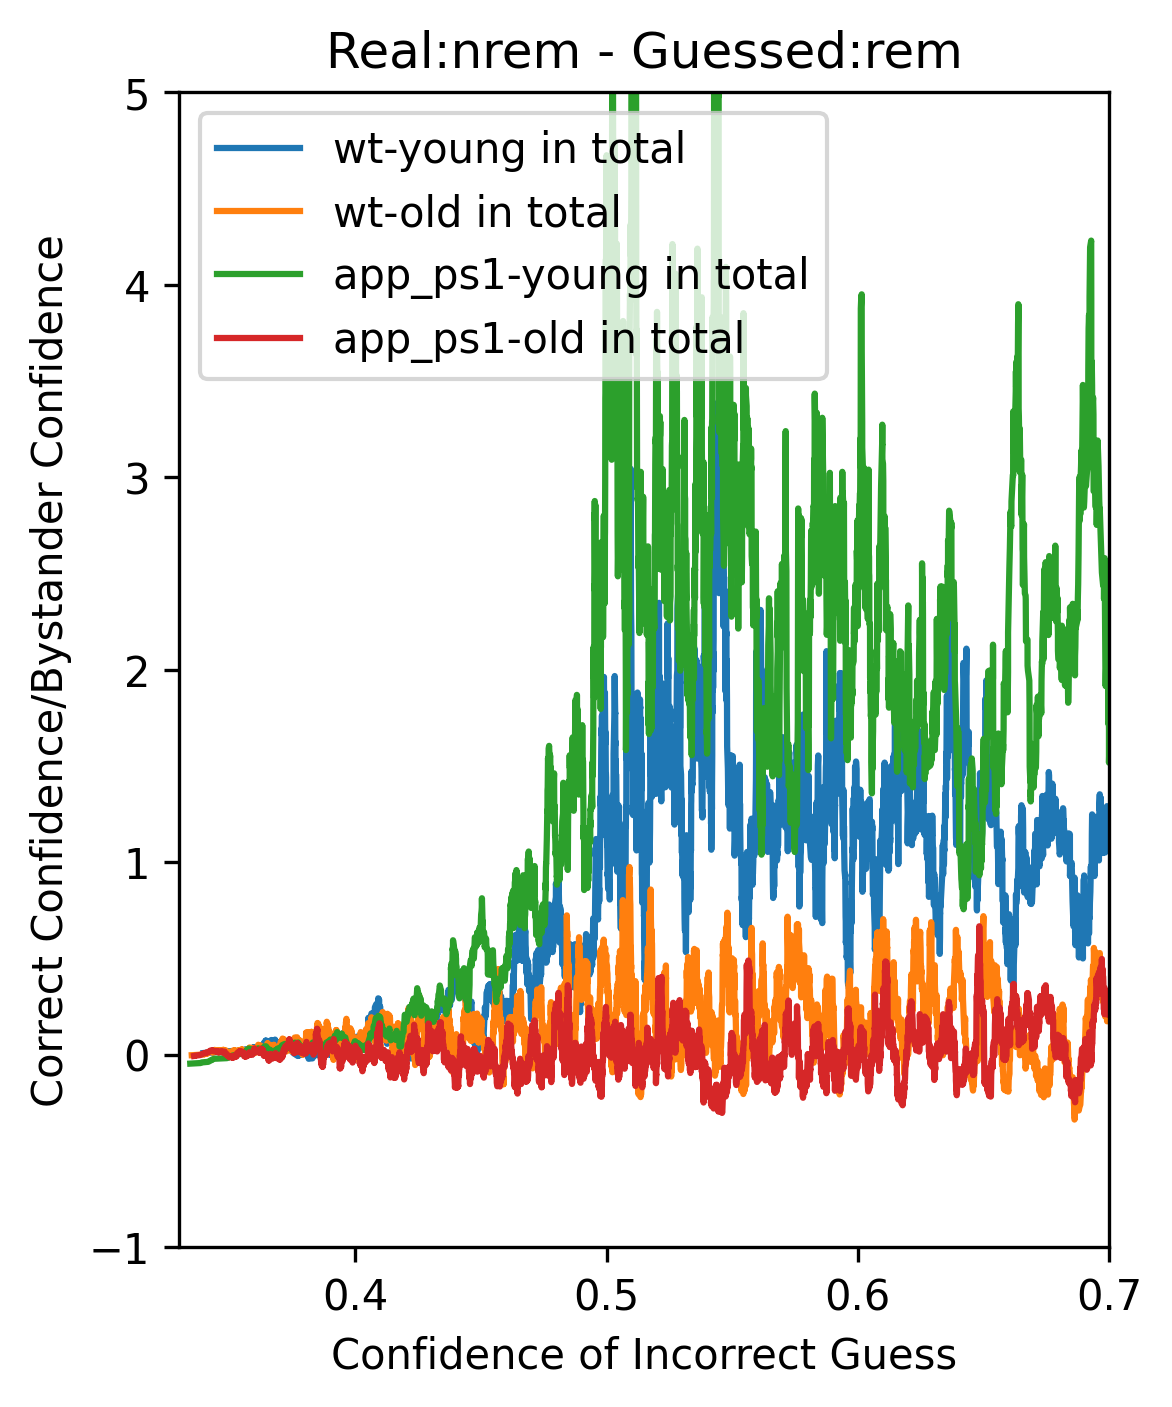

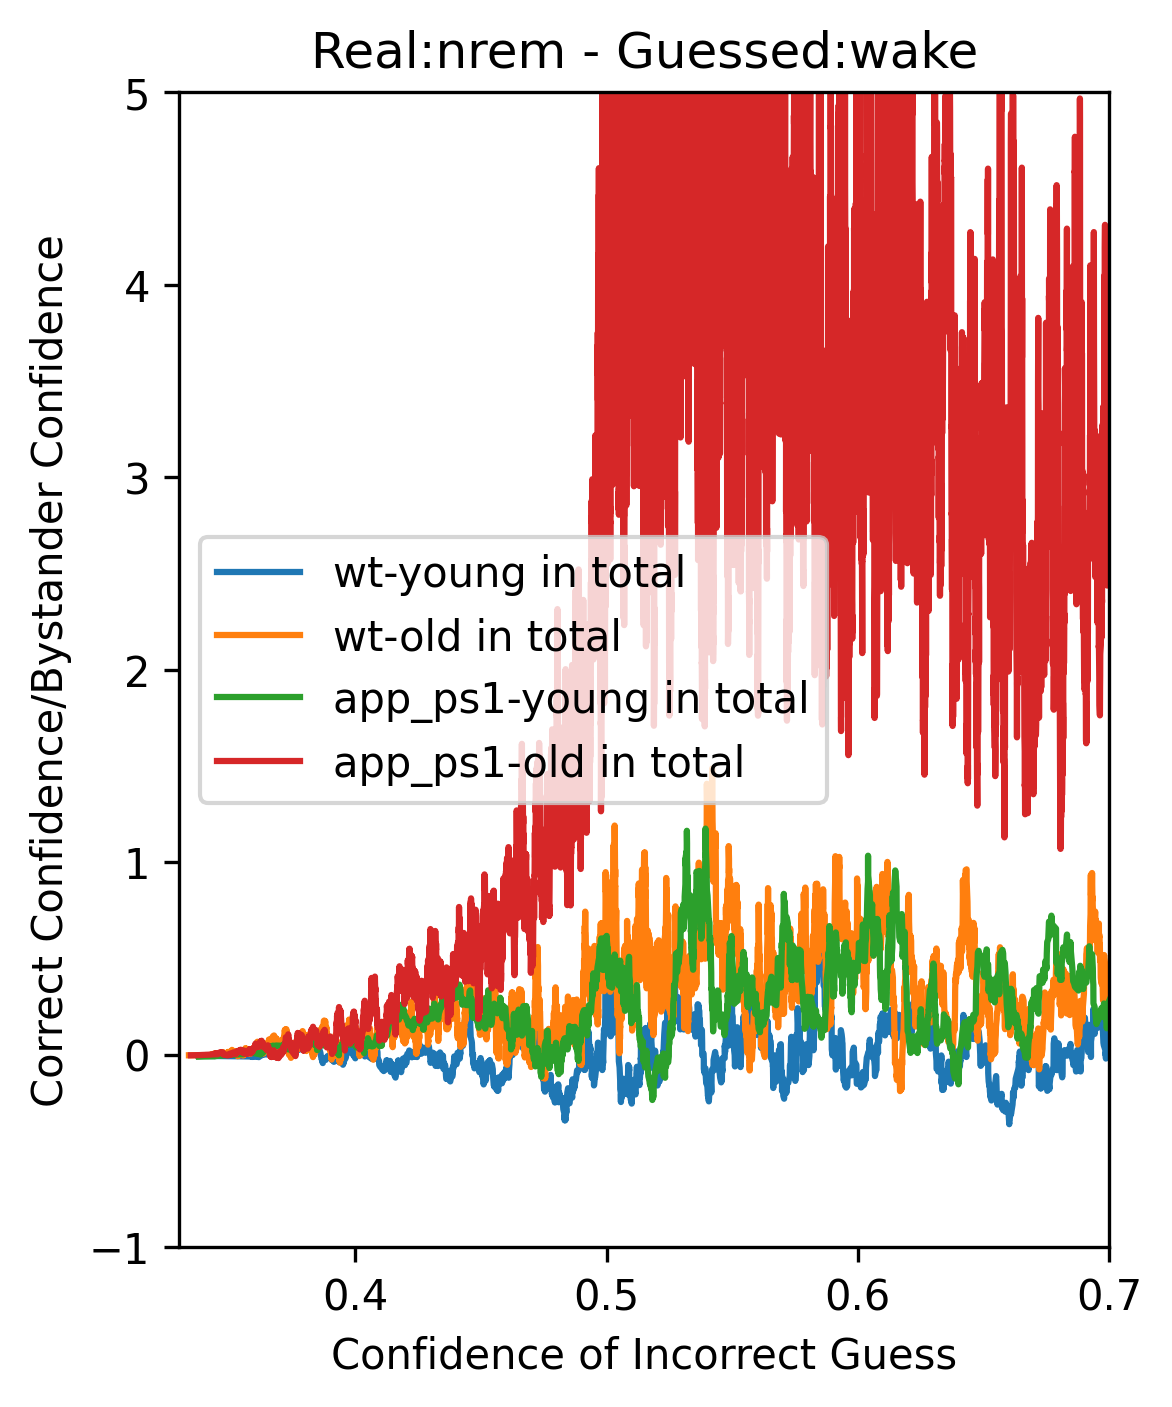

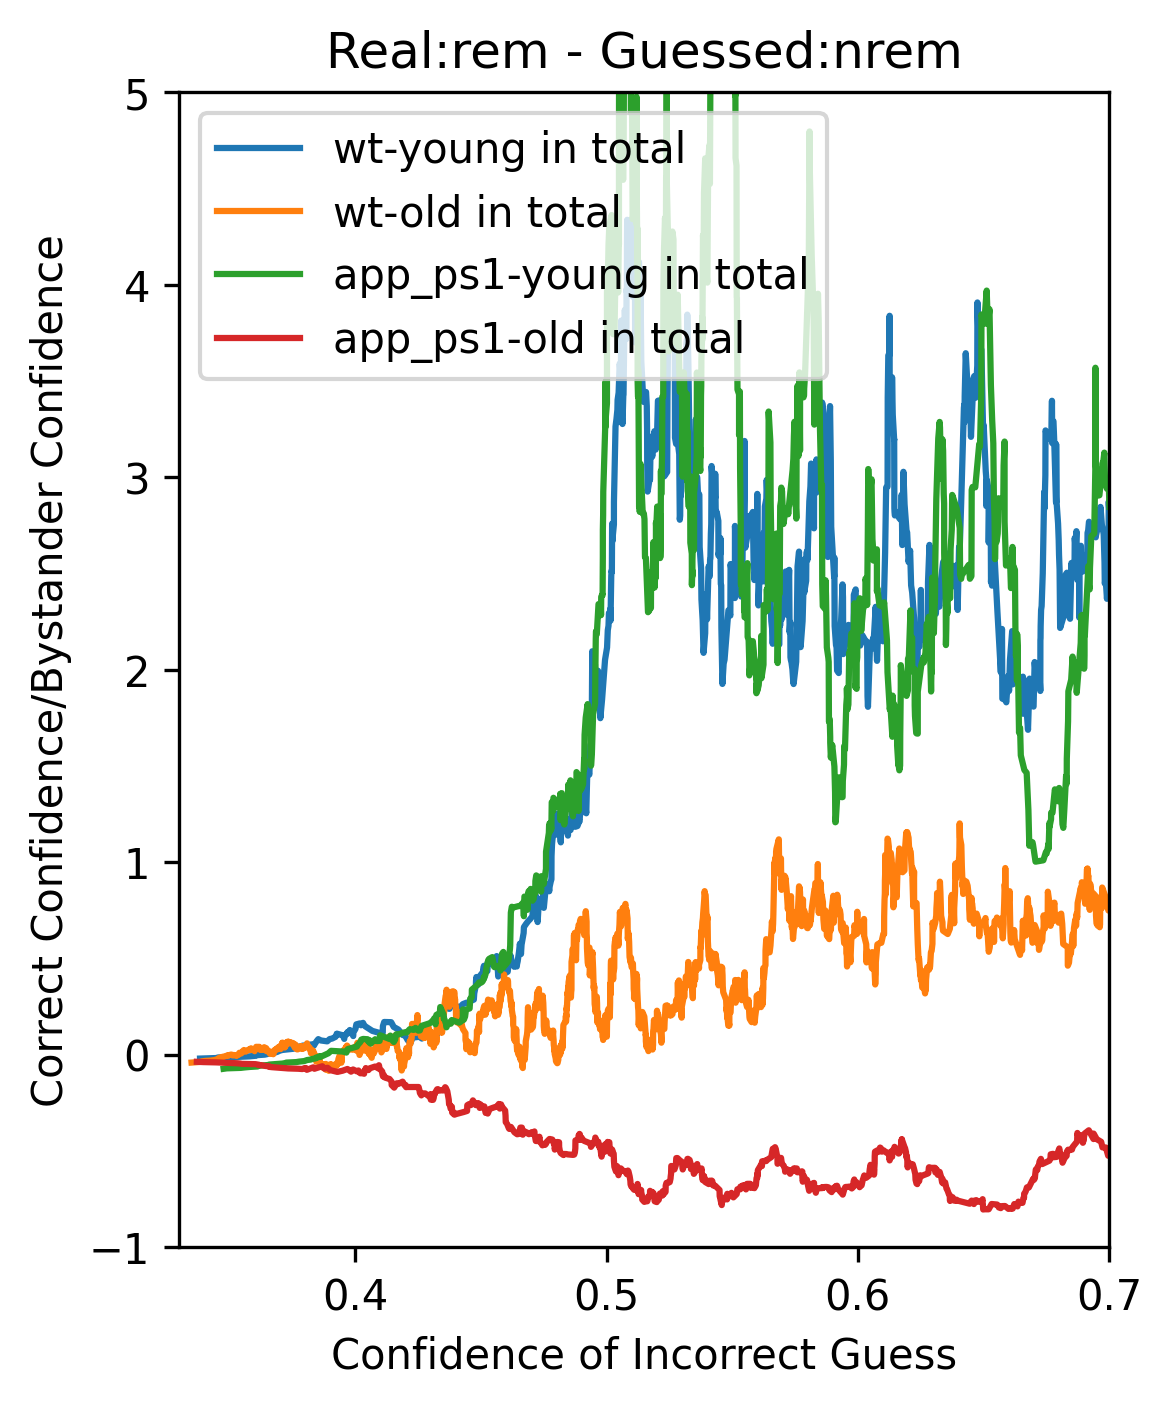

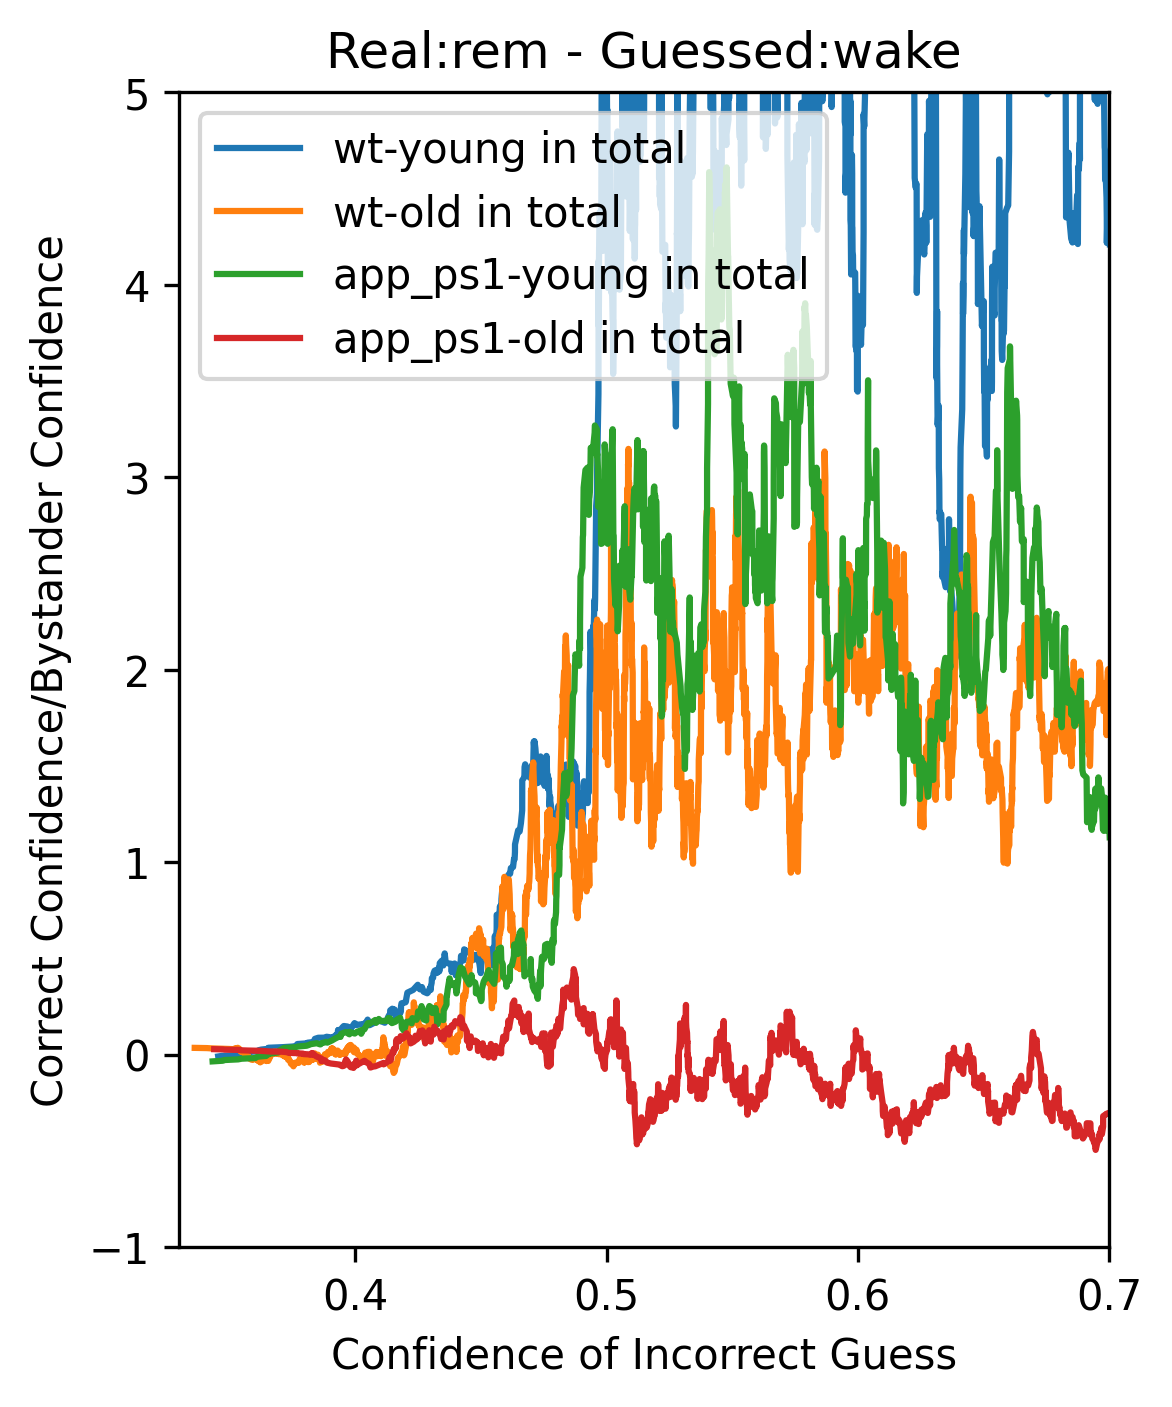

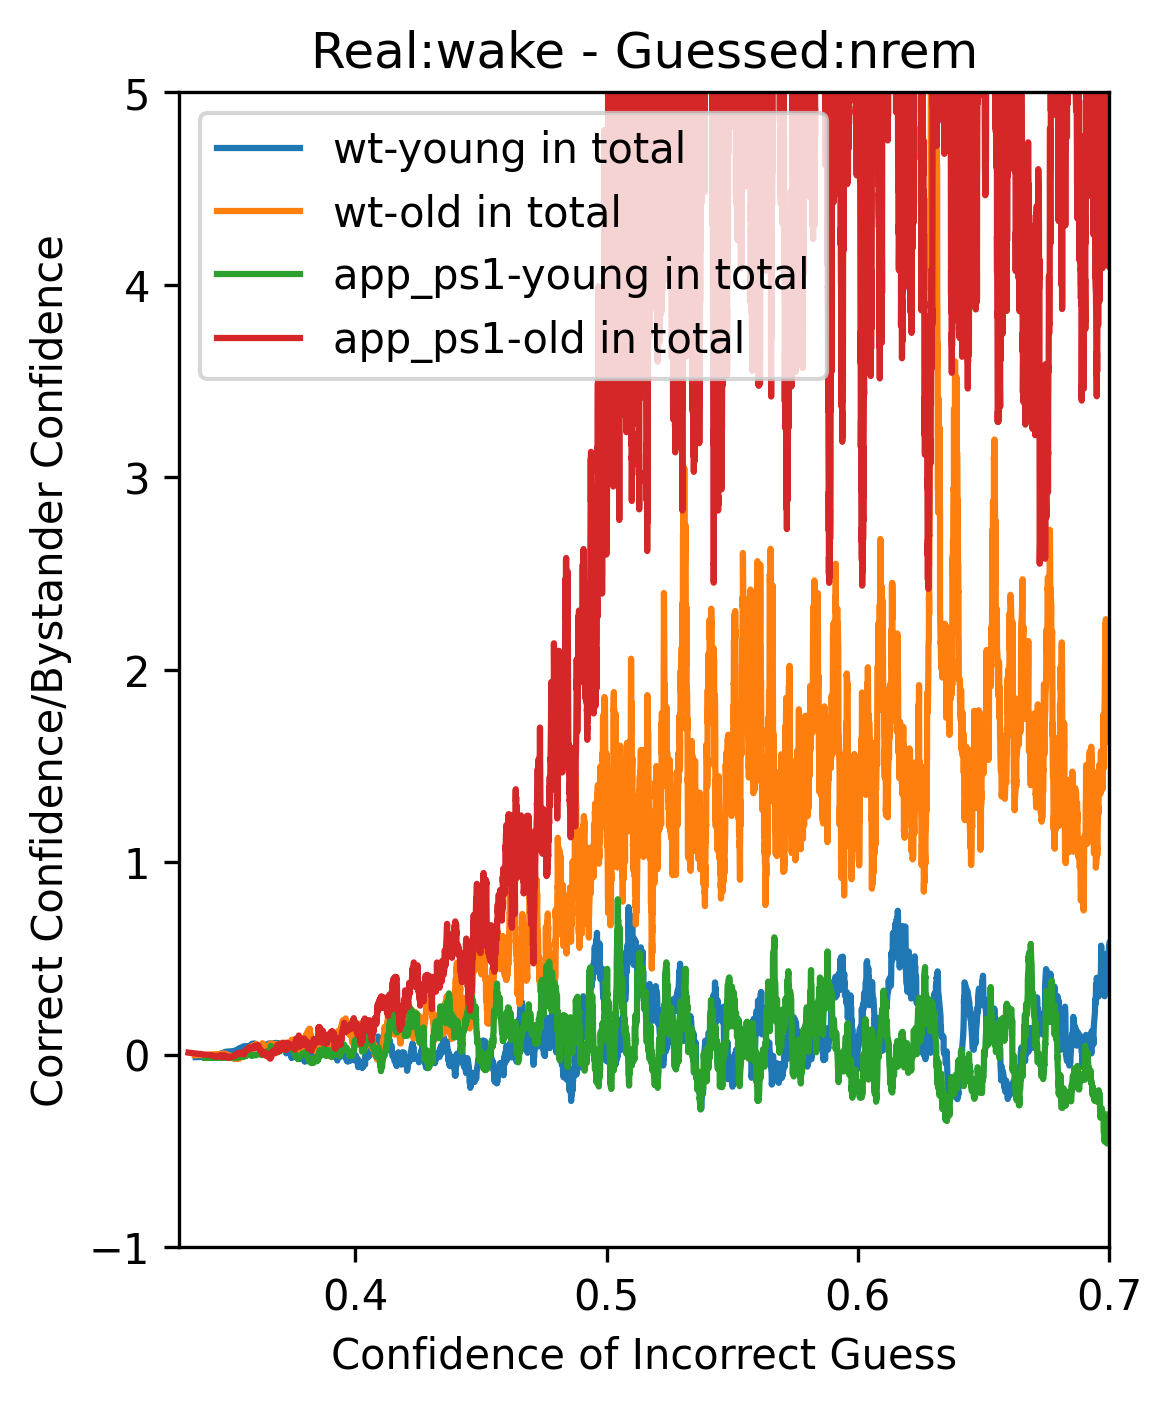

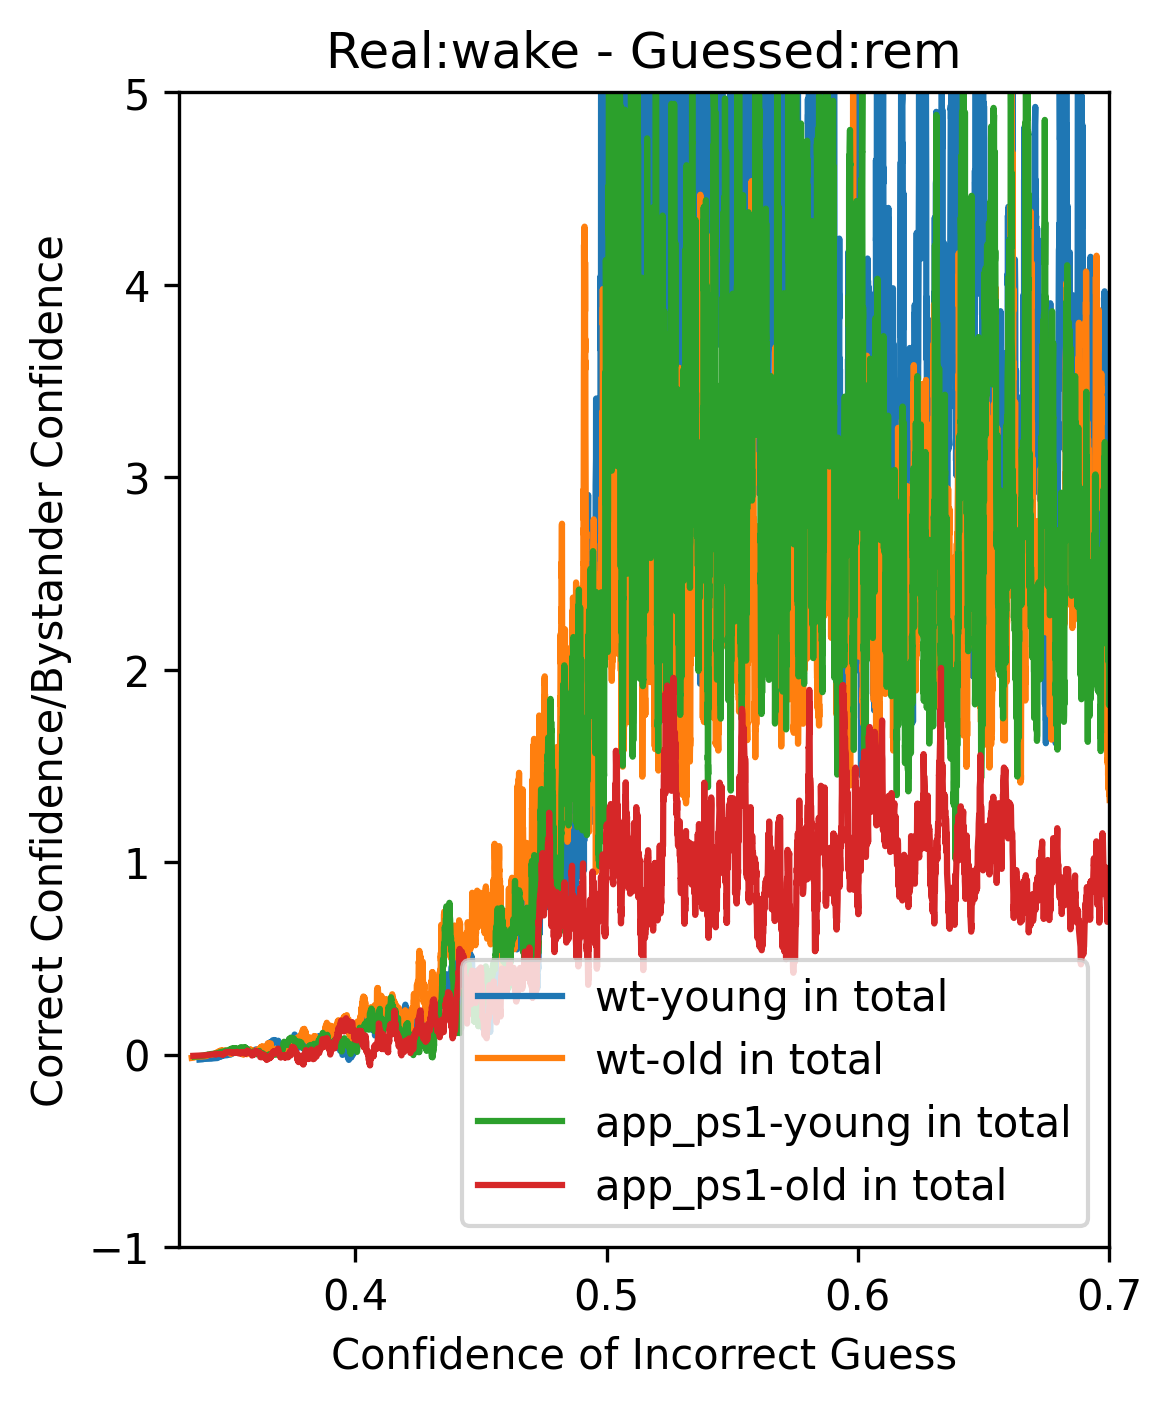

In [21]:
wrong_confidence_breakdown_by_state_ratio(graphic_train, cms["LogReg_over"], subplot_kwargs={"dpi":300, "figsize":(4,5)})

zbr106_101_0223_0_12_28_wt don't have a model :(


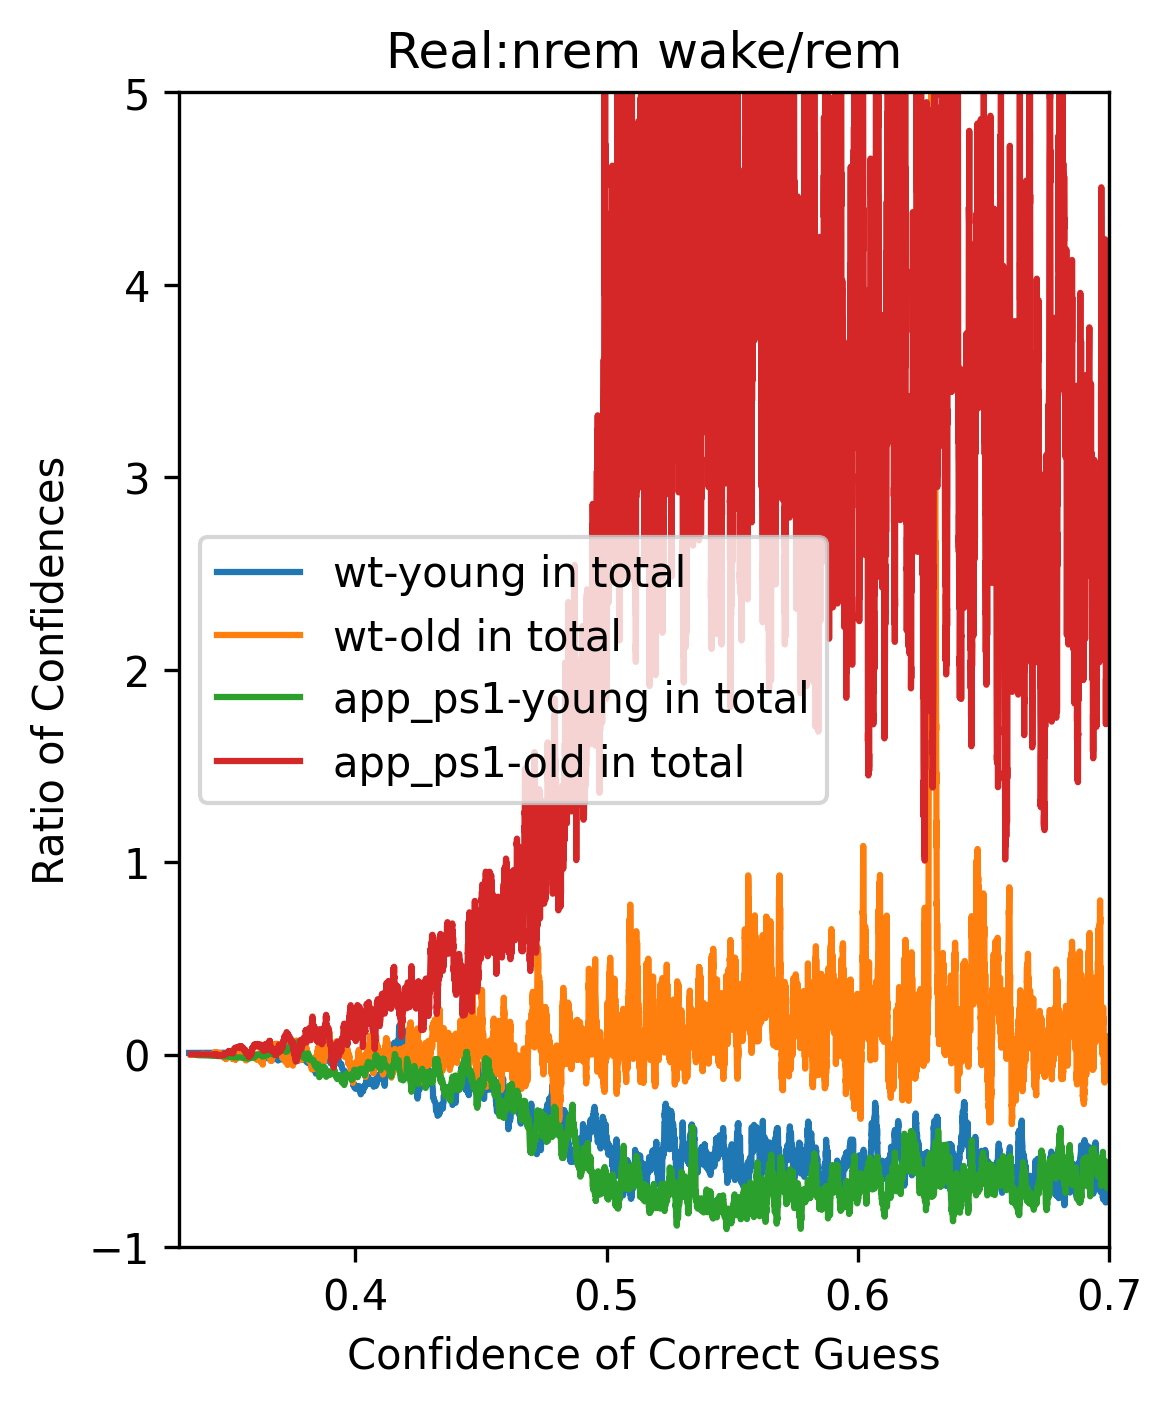

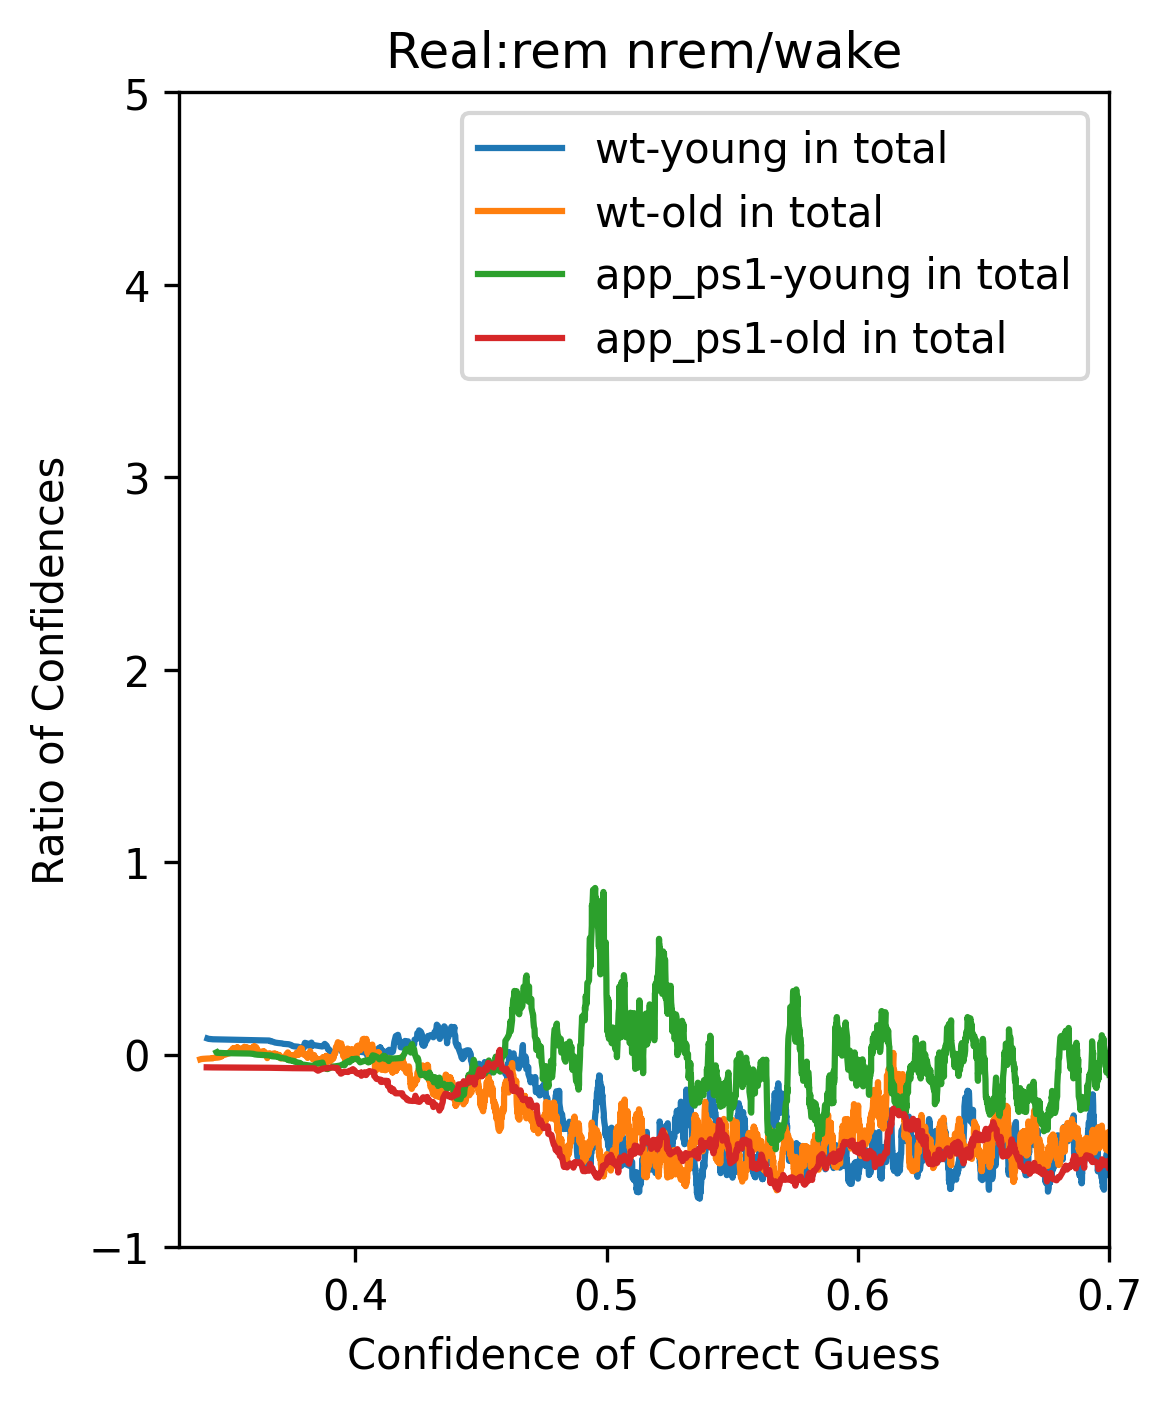

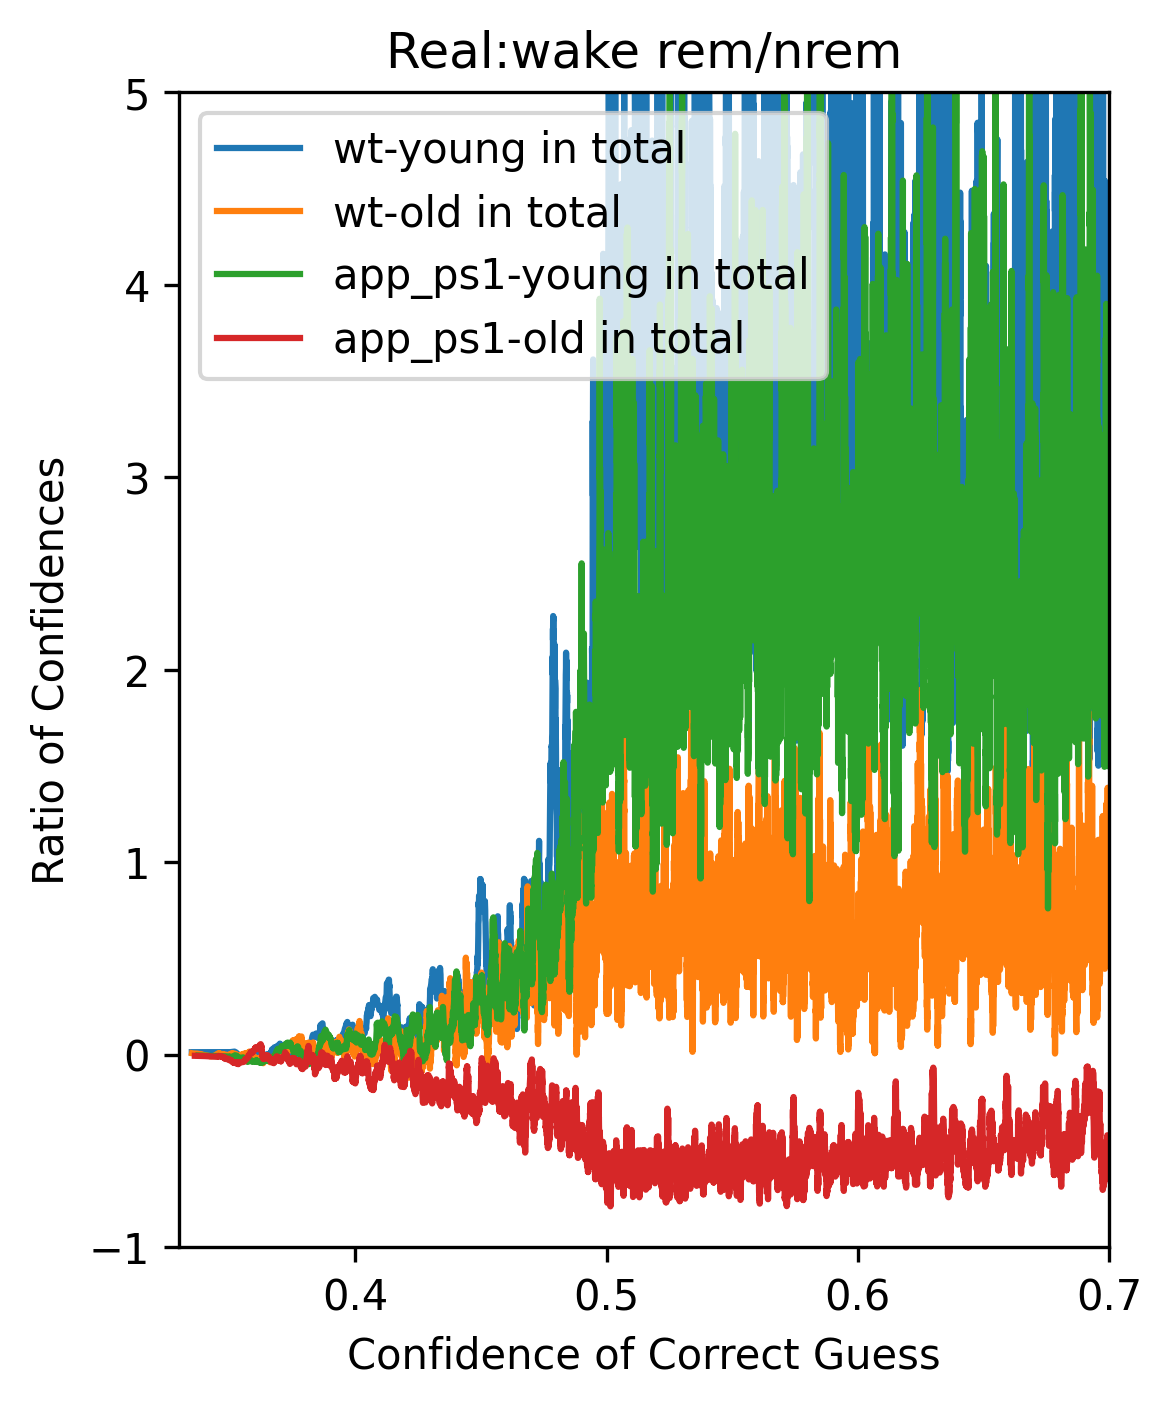

In [15]:
right_confidence_breakdown_by_state_ratio(graphic_train, cms["LogReg_over"], subplot_kwargs={"dpi":300, "figsize":(4,5)})

In [ ]:
fig, ax = plt.subplots(1,1, dpi=200, figsize=(9.5,4.5))
get_cm_distrib_hist(down_cms['LogReg_over'], down_graphic_train, f"NREM Accuracy Downsampled to Set Point in ACad", 
                    norm_size=3, kde=True, by_geno=True, by_age=True, by_region=True,
                    subset={'region':'ACad'},linewidth=4, bw_adjust=0.8, plot_eval=[lambda x:x[0][0]]
                   )

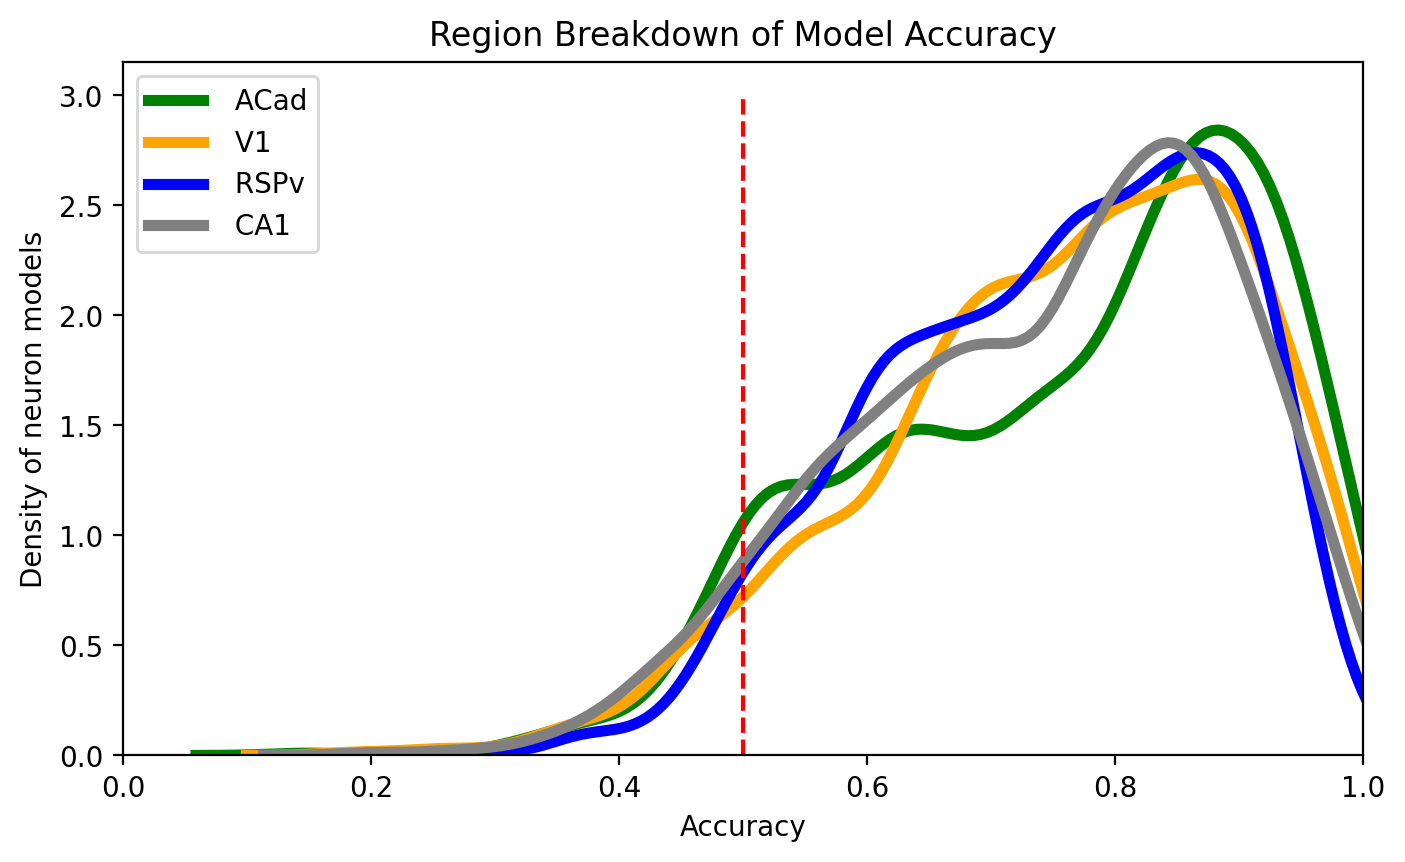

In [185]:
fig, ax = plt.subplots(1,1, dpi=200, figsize=(8,4.5))
get_cm_distrib_hist(sw_cms['LogReg_over'], graphic_train, f"Region Breakdown of Model Accuracy", 
                    norm_size=2, kde=True, by_region=True,
                    subset={},linewidth=4, bw_adjust=0.8,plot_eval=[accuracy], use_colors = ['g', 'orange', 'b', 'gray']
                   )

In [138]:
graphic_train = get_extended_condensed_data(train_scaled)

In [139]:
models = train_multi_models(train_scaled, sampling_types=['over'], methods=['LogReg'])
cms = get_cms_multi(test_scaled, models, get_spiking=True)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4316/4316 [00:13<00:00, 316.41it/s]


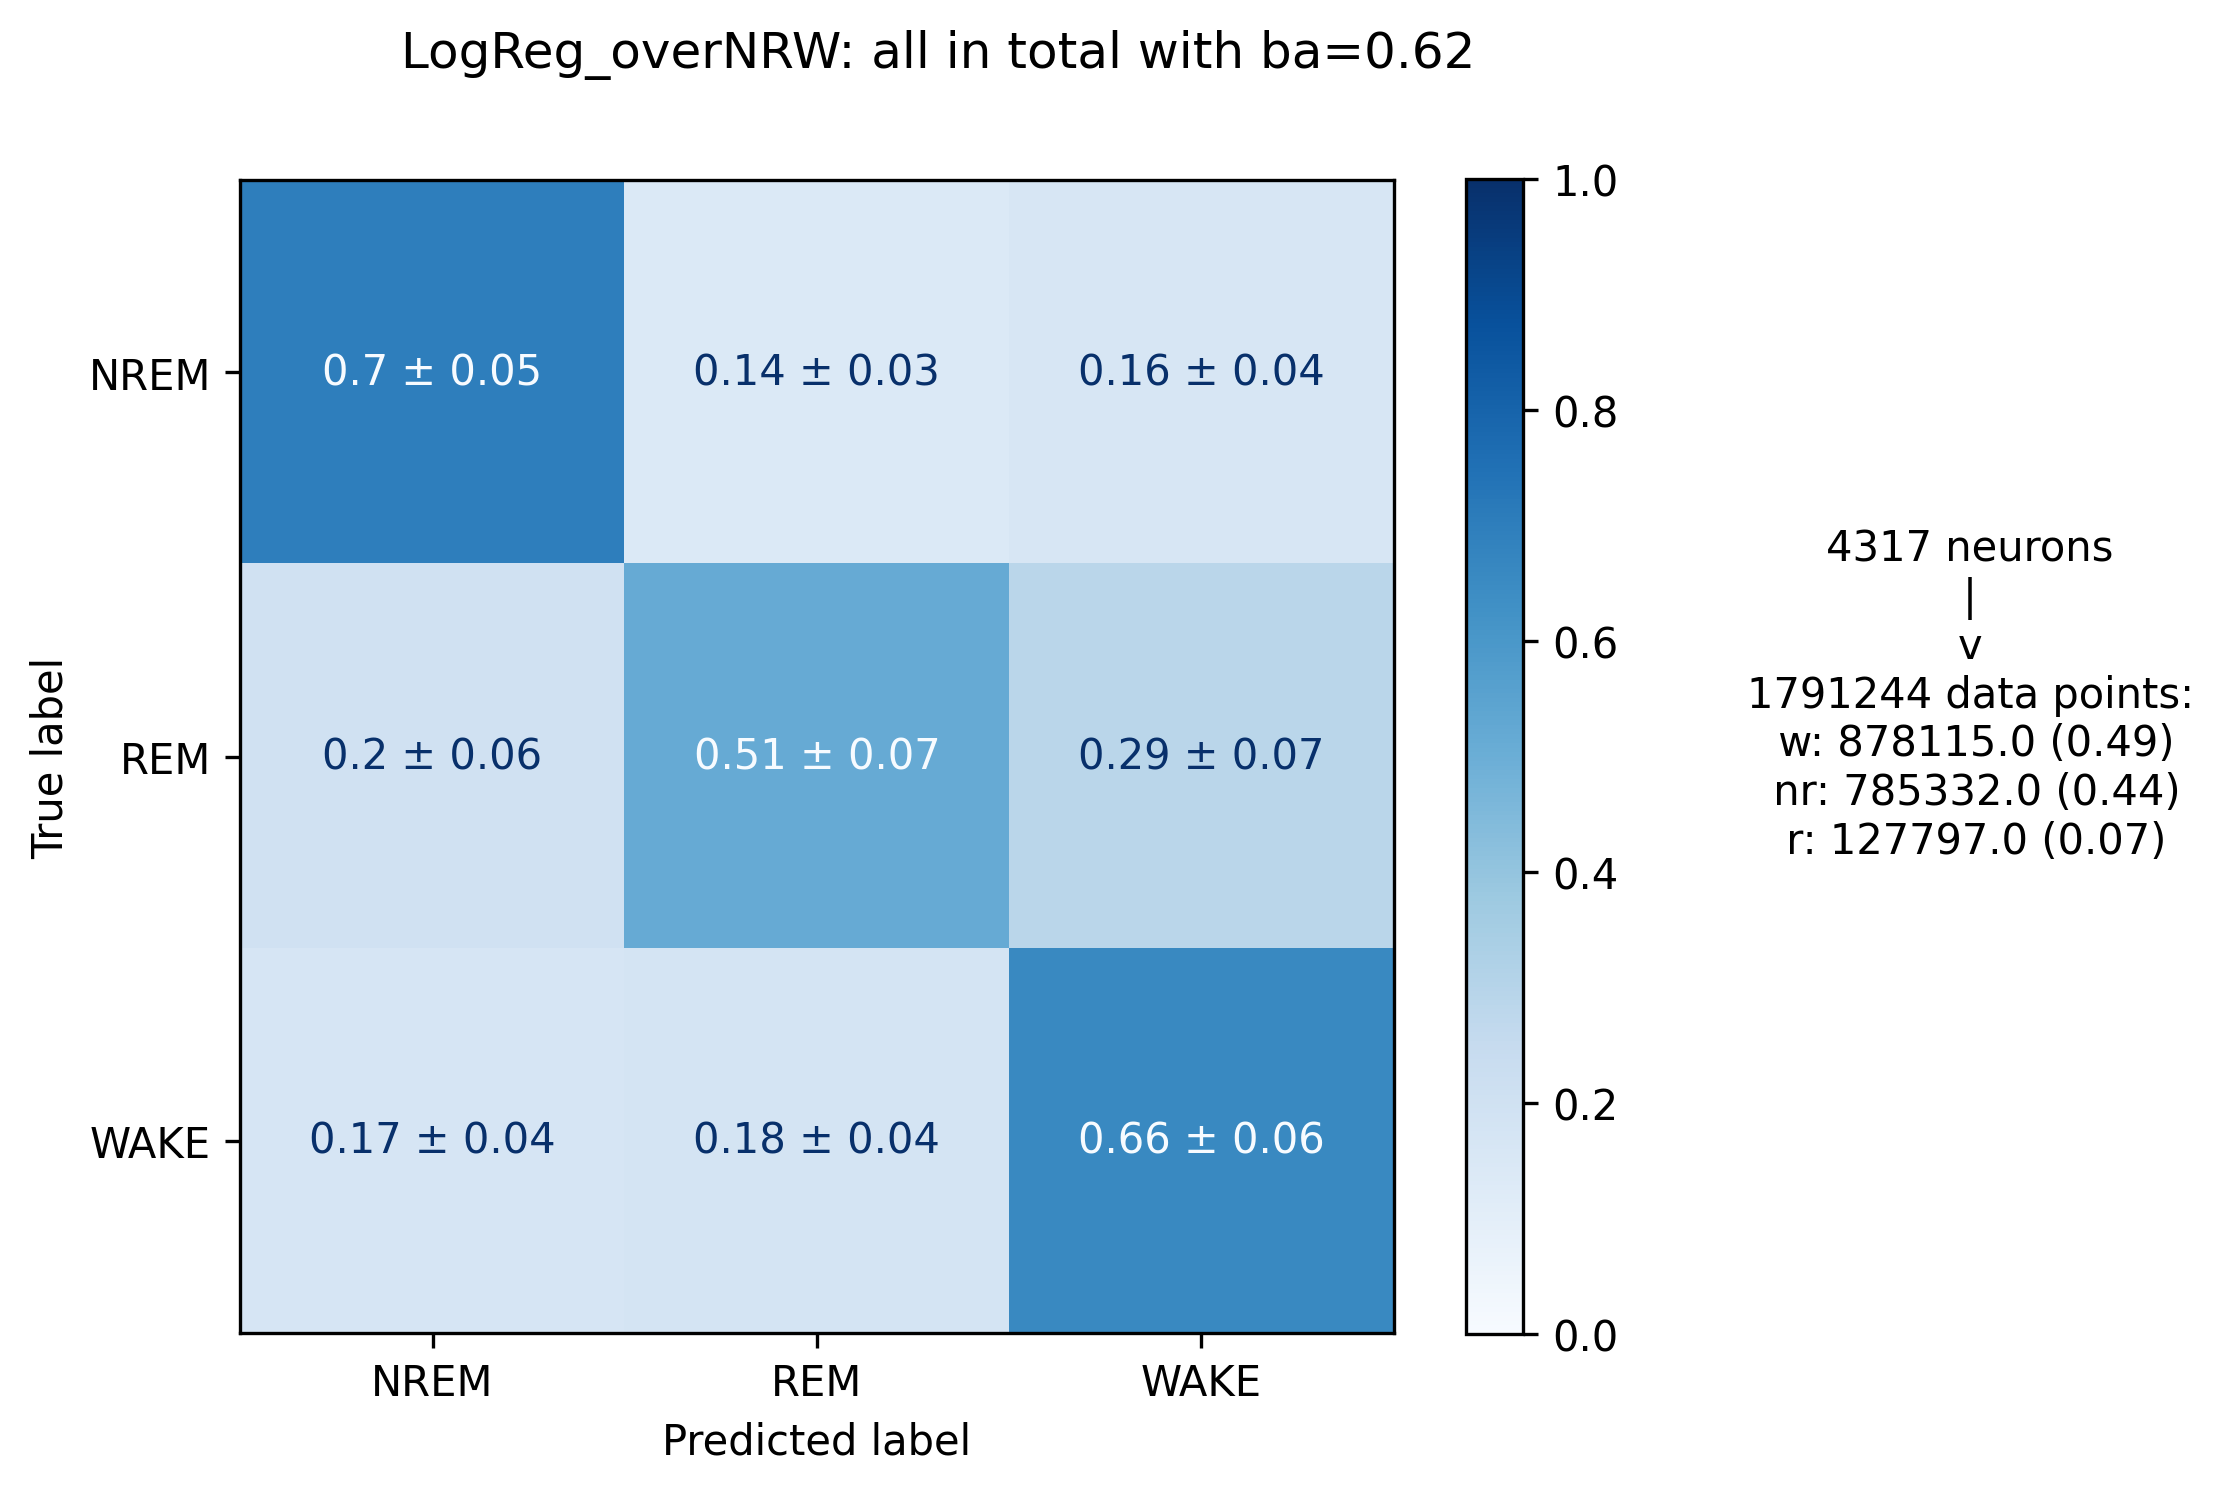

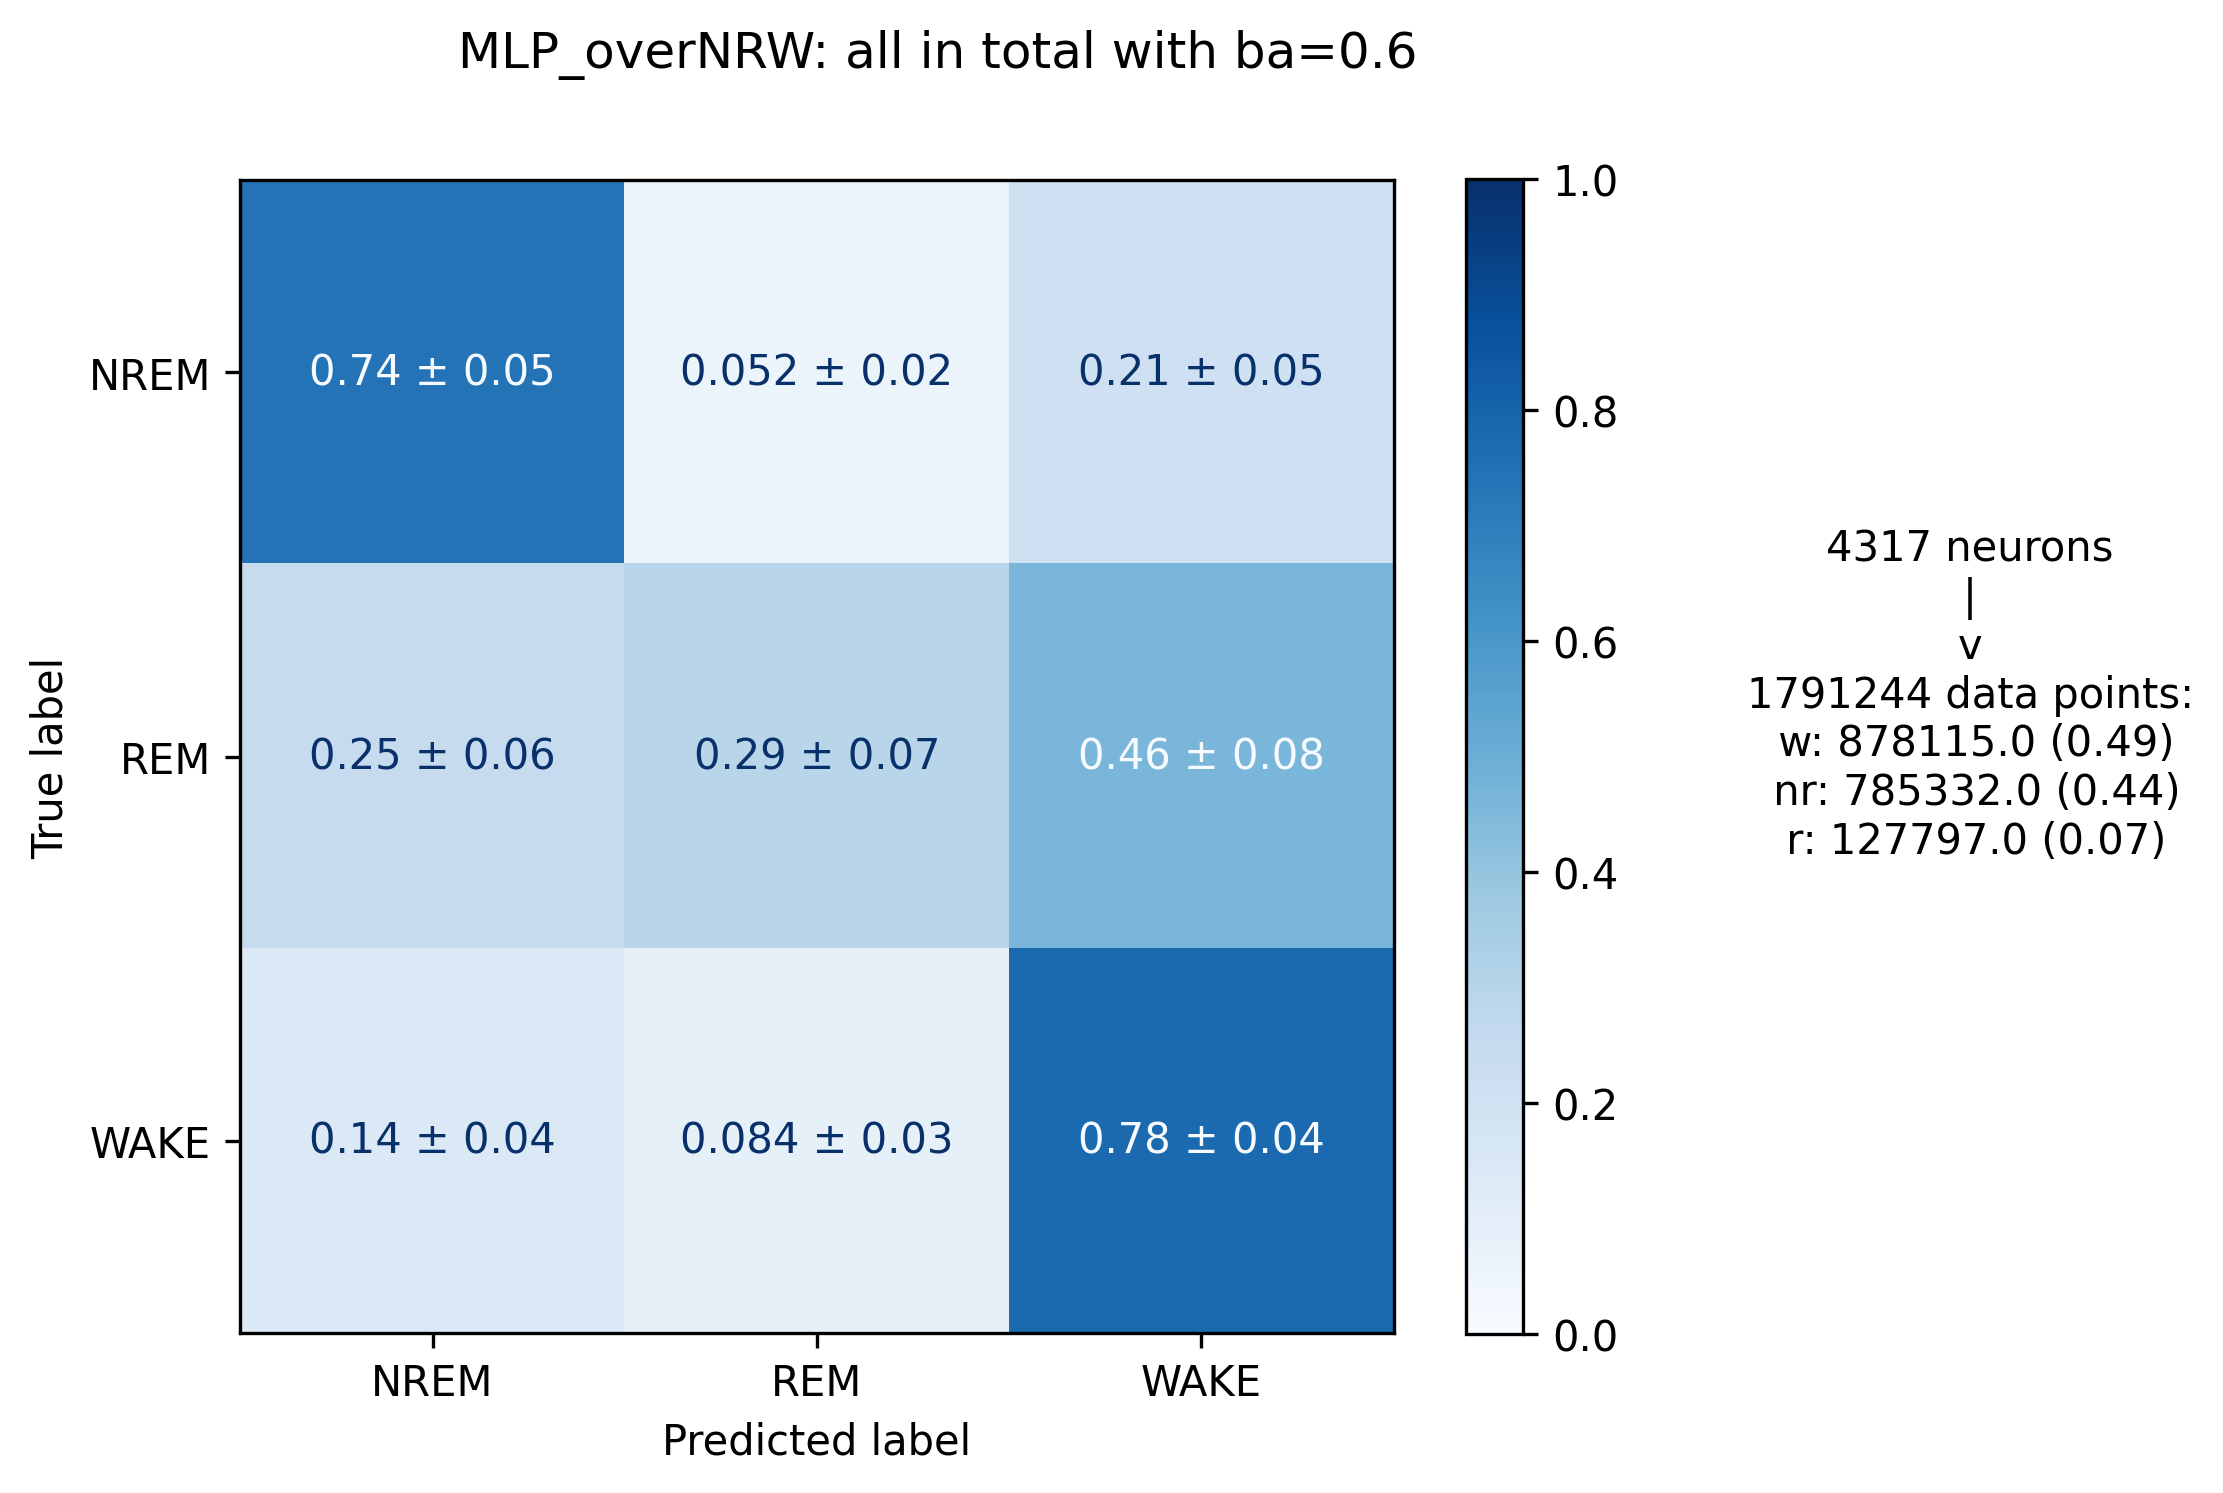

In [172]:
for key, val in cms.items():
    get_mean_cms_visual(val, graphic_train, f"{key}NRW", by_geno=False, by_age=False, subplot_kwargs={'figsize':(6.2,5), 'dpi':300}, 
                        addon_text=True, addon_suff='pres', parent_file_p='', savefig=True,
                       alt_se=True)

In [165]:
sw_train_scaled = get_sleep_state_conversion(train_scaled)
sw_test_scaled = get_sleep_state_conversion(test_scaled)

In [166]:
sw_models =  train_multi_models(sw_train_scaled, sampling_types=['over'], methods=['LogReg'],
                               num_states=2)
sw_models = sw_models | train_multi_models(sw_train_scaled, sampling_types=['smote'], methods=['XGBoost'],
                               num_states=2)

 15%|████████████████▌                                                                                                | 634/4317 [00:40<03:28, 17.62it/s]

sad, this failed Expected n_neighbors <= n_samples_fit, but n_neighbors = 6, n_samples_fit = 2, n_samples = 2


 69%|█████████████████████████████████████████████████████████████████████████████▋                                  | 2996/4317 [02:59<00:48, 27.28it/s]

sad, this failed Expected n_neighbors <= n_samples_fit, but n_neighbors = 6, n_samples_fit = 3, n_samples = 3
sad, this failed Expected n_neighbors <= n_samples_fit, but n_neighbors = 6, n_samples_fit = 3, n_samples = 3


 70%|█████████████████████████████████████████████████████████████████████████████▉                                  | 3006/4317 [02:59<00:37, 34.95it/s]

...

 81%|███████████████████████████████████████████████████████████████████████████████████████████                     | 3512/4317 [03:22<00:20, 40.15it/s]

sad, this failed Expected n_neighbors <= n_samples_fit, but n_neighbors = 6, n_samples_fit = 4, n_samples = 4


 82%|███████████████████████████████████████████████████████████████████████████████████████████▉                    | 3544/4317 [03:22<00:17, 43.03it/s]

sad, this failed Expected n_neighbors <= n_samples_fit, but n_neighbors = 6, n_samples_fit = 3, n_samples = 3


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4317/4317 [03:59<00:00, 18.06it/s]


In [167]:
sw_cms = get_cms_multi(sw_test_scaled, sw_models, get_spiking=True)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4292/4292 [00:28<00:00, 149.89it/s]


In [133]:
condensed_sw = get_extended_condensed_data(sw_train_scaled)
#merge_accuracy_neuron(sw_cms['LogReg_over'], condensed_sw, save=True, name='sw_logreg_over', num_state=2)

,index,region,cell,animal,celltype,geno,cell_no,age,age_group,state_chunks_sleep,state_chunks_wake,balanced_acc,wake_acc,sleep_acc
1,414,ACad,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,177,414,0.948052,1.000000,0.896104
3,657,ACad,caf69_358_1228_0_12_1_wt,caf69,RSU,wt,1,358,old,72,66,0.898810,0.964286,0.833333
5,847,ACad,caf69_358_1228_0_12_2_wt,caf69,RSU,wt,2,358,old,79,118,0.895833,1.000000,0.791667
7,1107,ACad,caf69_358_1228_0_12_3_wt,caf69,RSU,wt,3,358,old,80,181,0.980000,1.000000,0.960000
9,1361,ACad,caf69_358_1228_0_12_4_wt,caf69,RSU,wt,4,358,old,78,174,0.937500,1.000000,0.875000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8625,1787525,V1,bth100_99_0624_12_24_90_wt,bth100,RSU,wt,90,99,young,72,220,0.963964,0.927928,1.000000
8627,1787996,V1,bth100_99_0624_12_24_91_wt,bth100,RSU,wt,91,99,young,161,399,0.849802,0.942029,0.757576
8629,1788356,V1,bth100_99_0624_12_24_92_wt,bth100,RSU,wt,92,99,young,110,199,0.671205,0.425743,0.916667
8631,1789623,V1,bth100_99_0624_12_24_93_wt,bth100,FS,wt,93,99,young,612,1157,0.565566,0.429984,0.701149


In [170]:
with open(f"/media/HlabShare/Toby_work/sleep_indiv_neuron/mlp_cms/baseline.pkl", "rb") as f:
    mlp_cms = pickle.load(f)

In [171]:
cms = cms | {'MLP_over':mlp_cms}

In [168]:
sleep_cond = get_extended_condensed_data(sw_train_scaled)

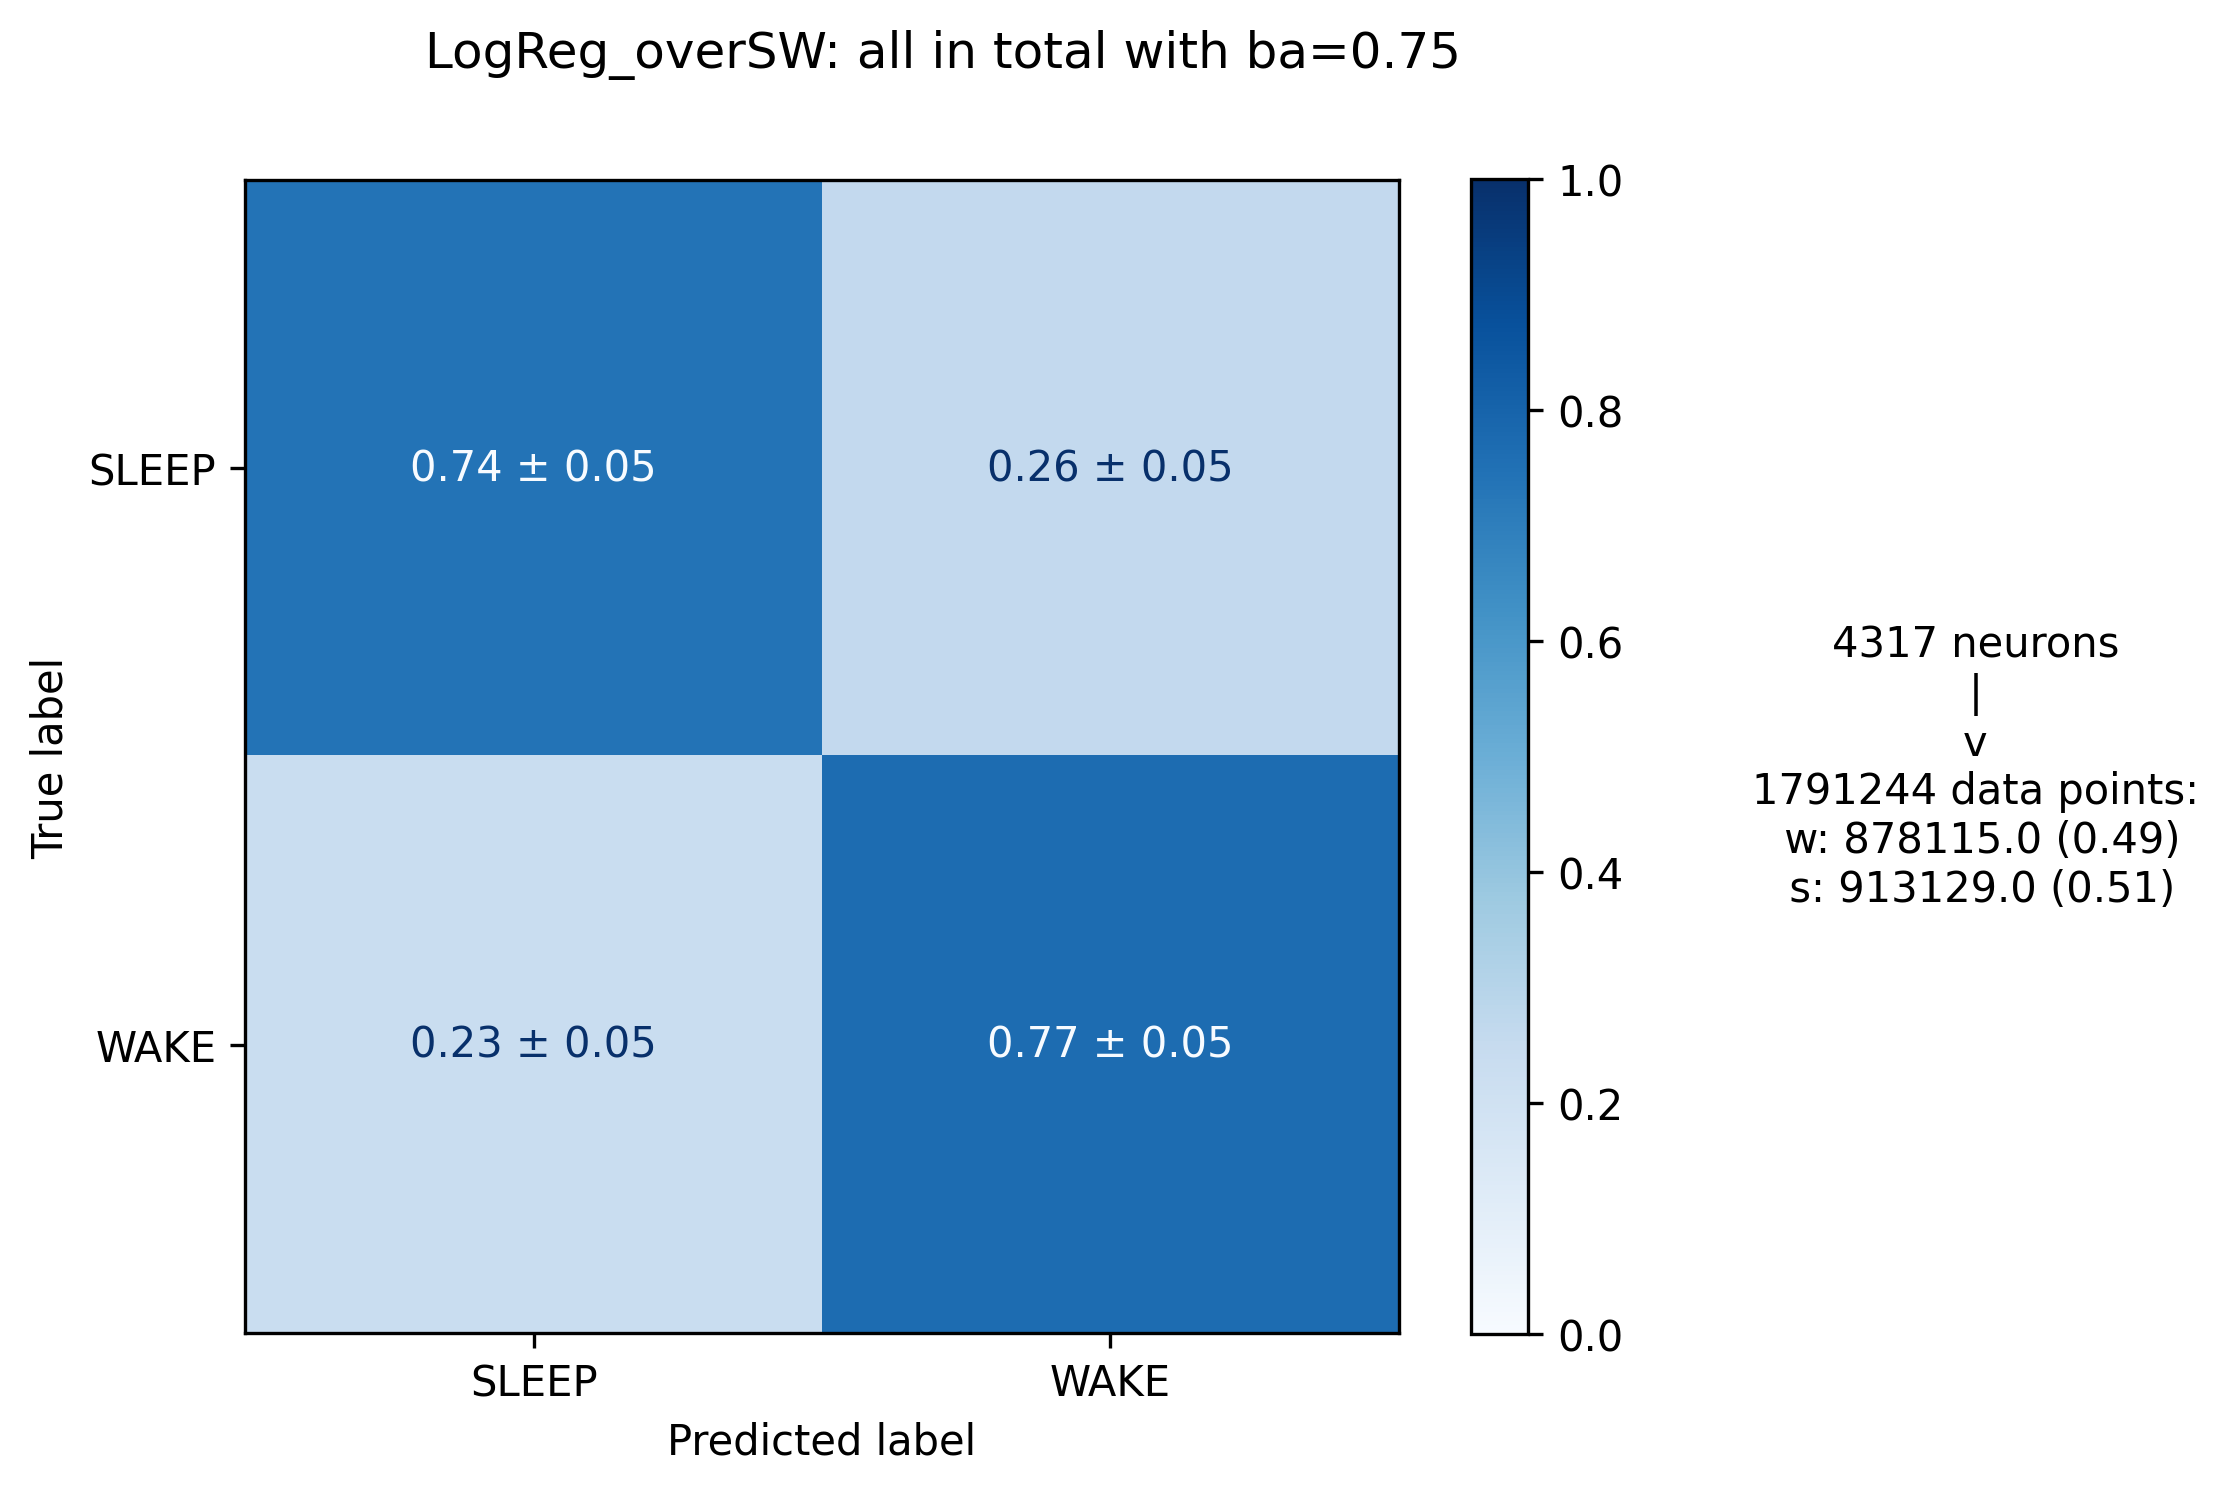

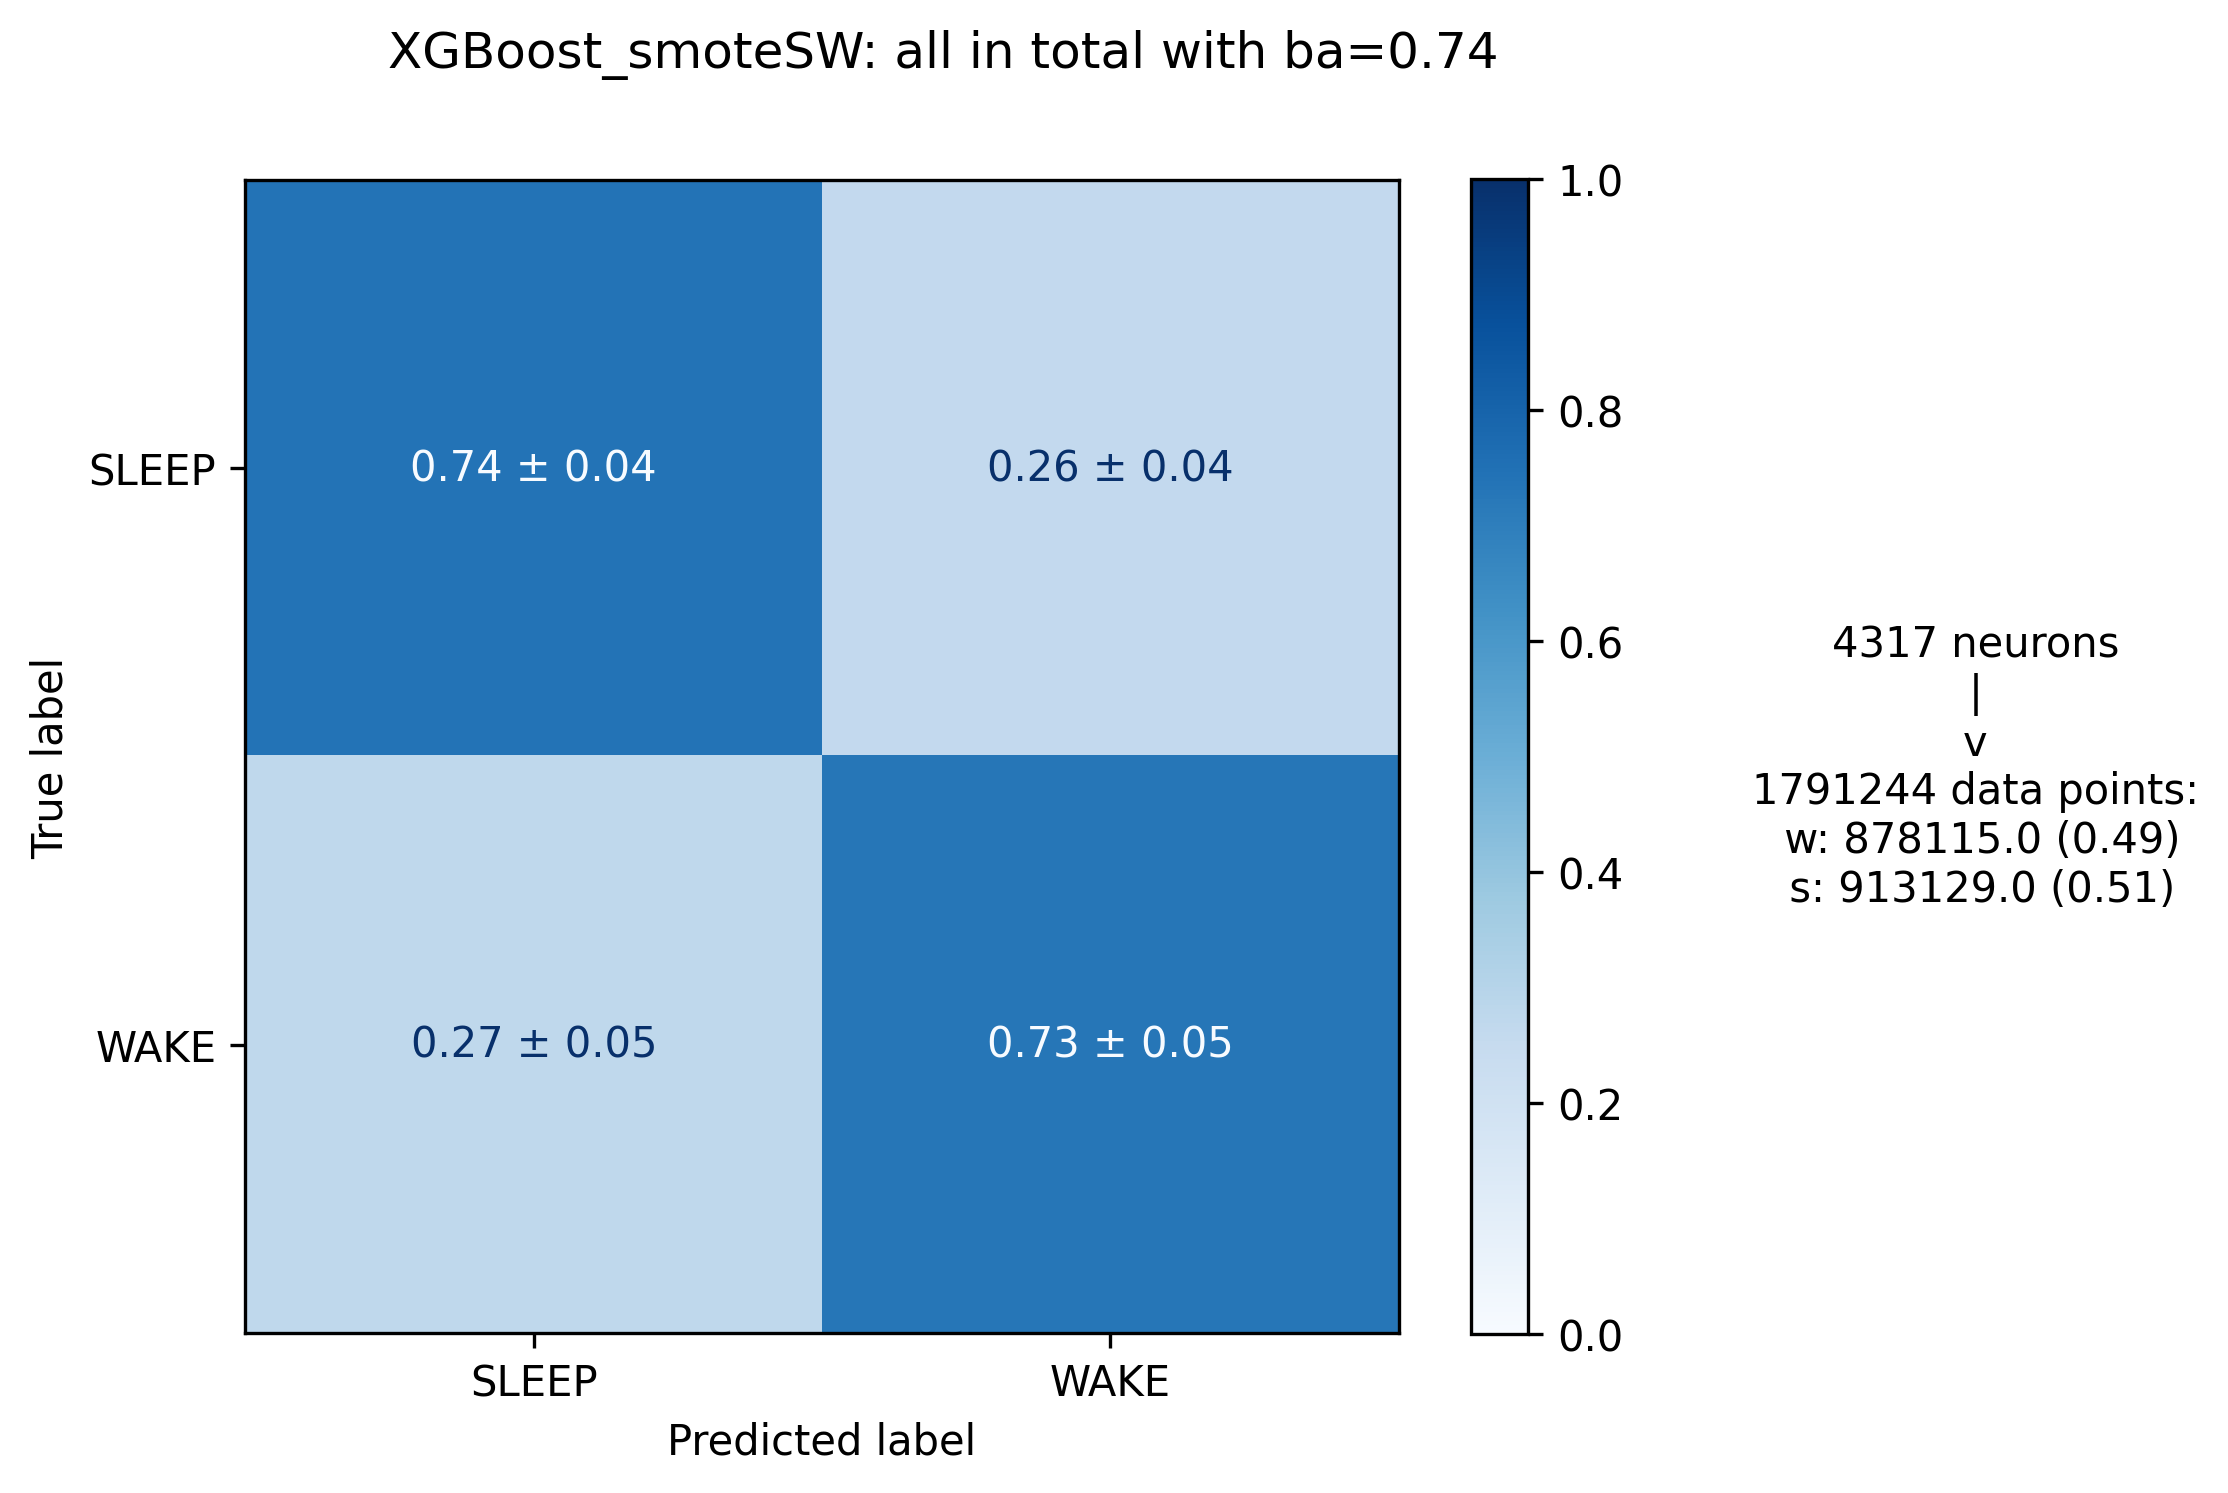

In [169]:
for key, val in sw_cms.items():
    get_mean_cms_visual(val, sleep_cond, f"{key}SW", by_geno=False, by_age=False, subplot_kwargs={'figsize':(6.2,5), 'dpi':300}, 
                        addon_text=True, addon_suff='pres', parent_file_p='', savefig=True, norm_size=2, alt_se=True,
                       )

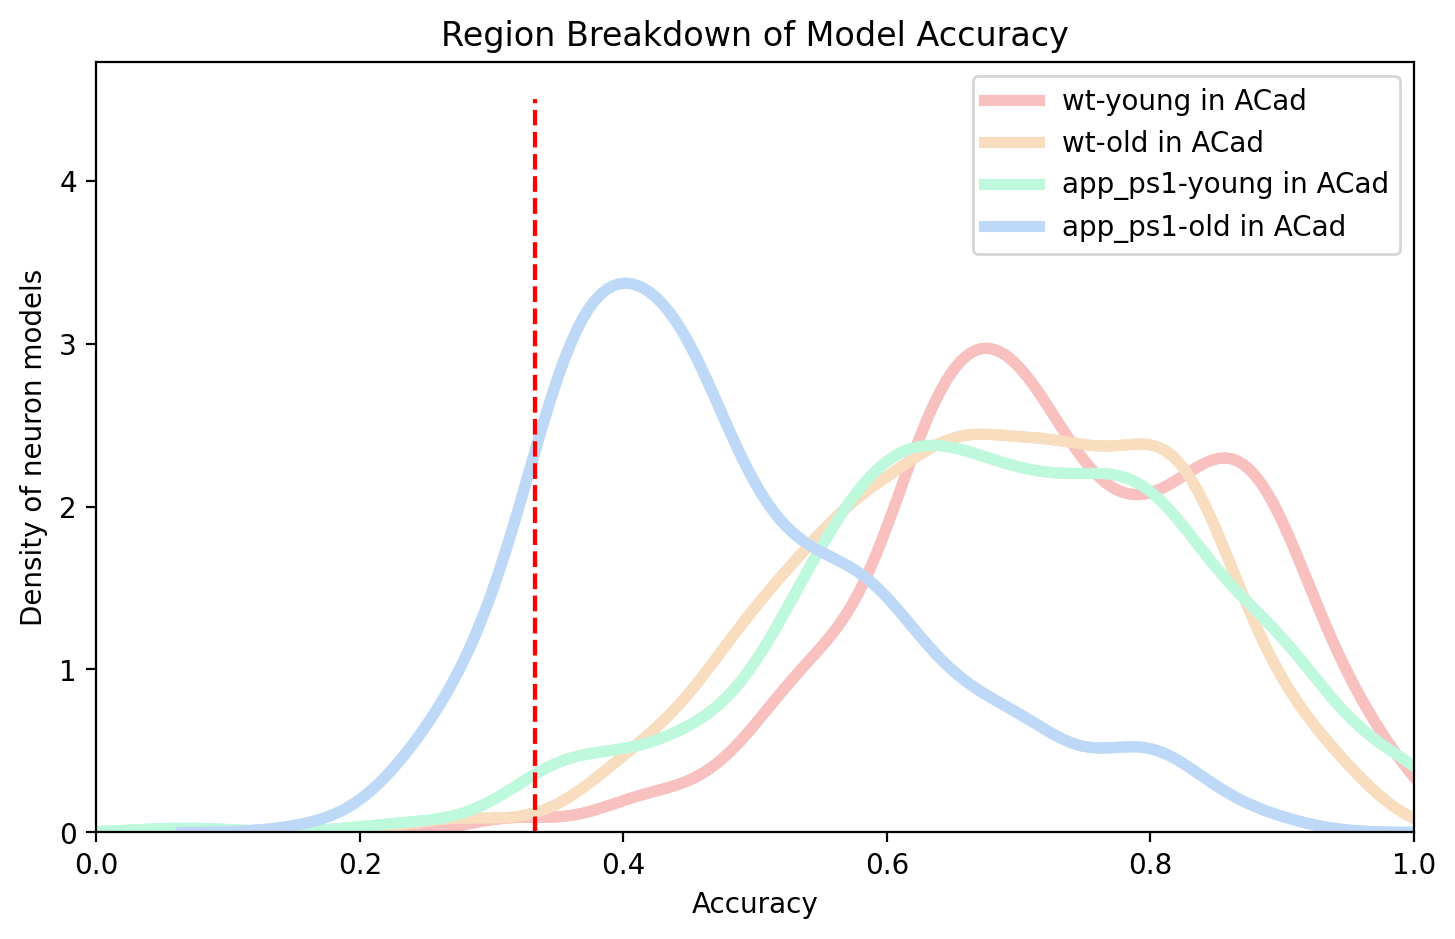

In [195]:
maybe_colors = [(248/255, 192/255, 190/255),(248/255, 221/255, 190/255),
                                (190/255, 248/255, 221/255),(190/255, 217/255, 248/255)]
fig, ax = plt.subplots(1,1, dpi=200, figsize=(8.5,5))
get_cm_distrib_hist(cms['LogReg_over'], graphic_train, f"Region Breakdown of Model Accuracy", 
                    norm_size=3, kde=True, by_region=True, by_geno=True,by_age=True,
                    subset={'region':'ACad'},linewidth=4, bw_adjust=0.8, use_colors=maybe_colors
                   )

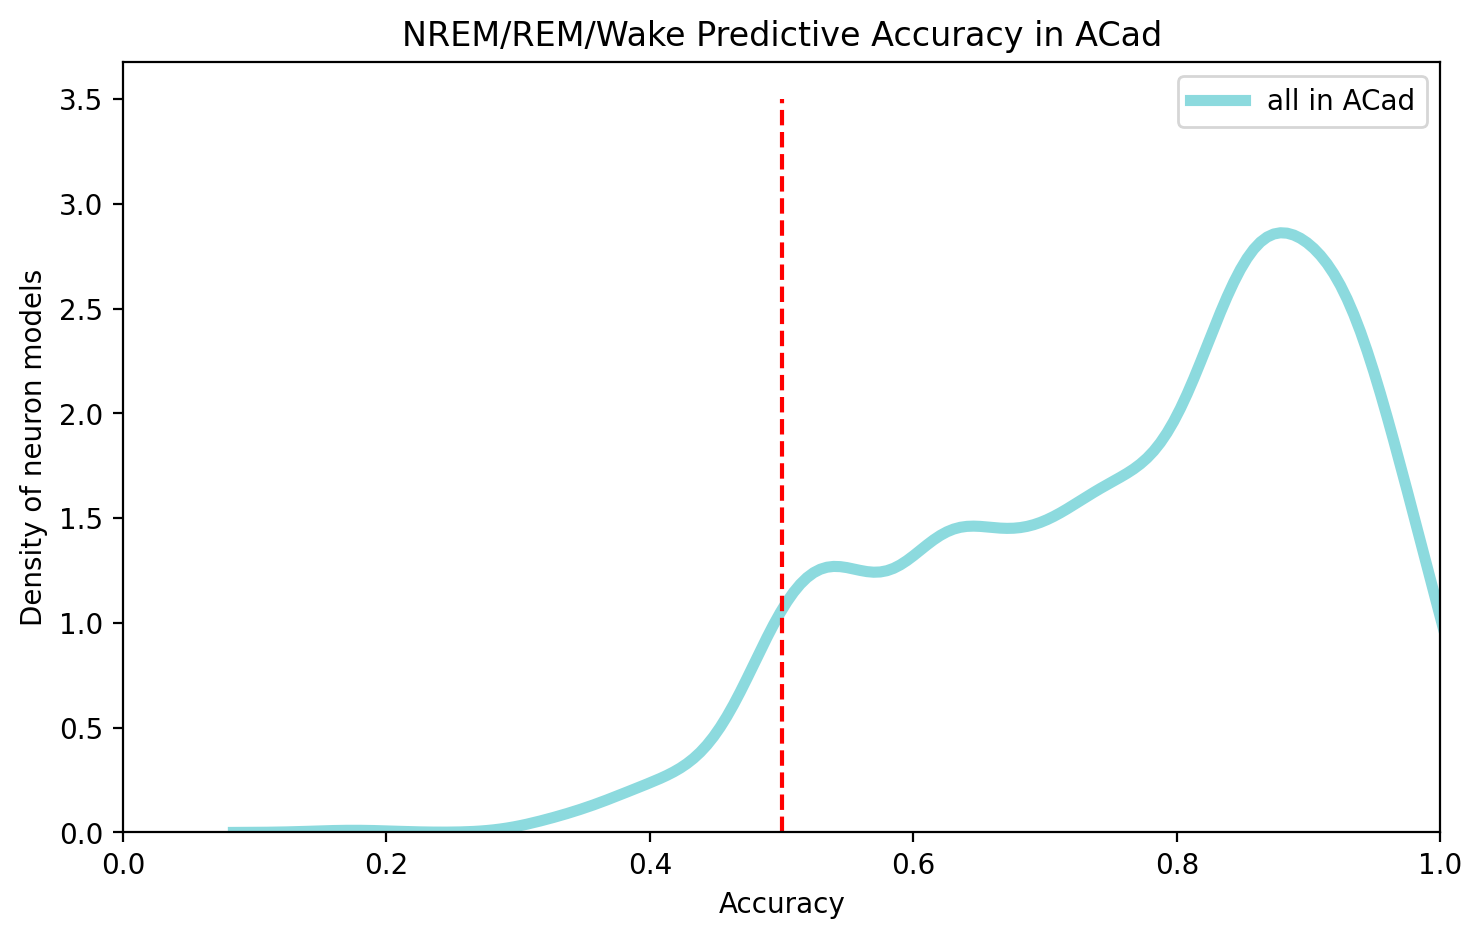

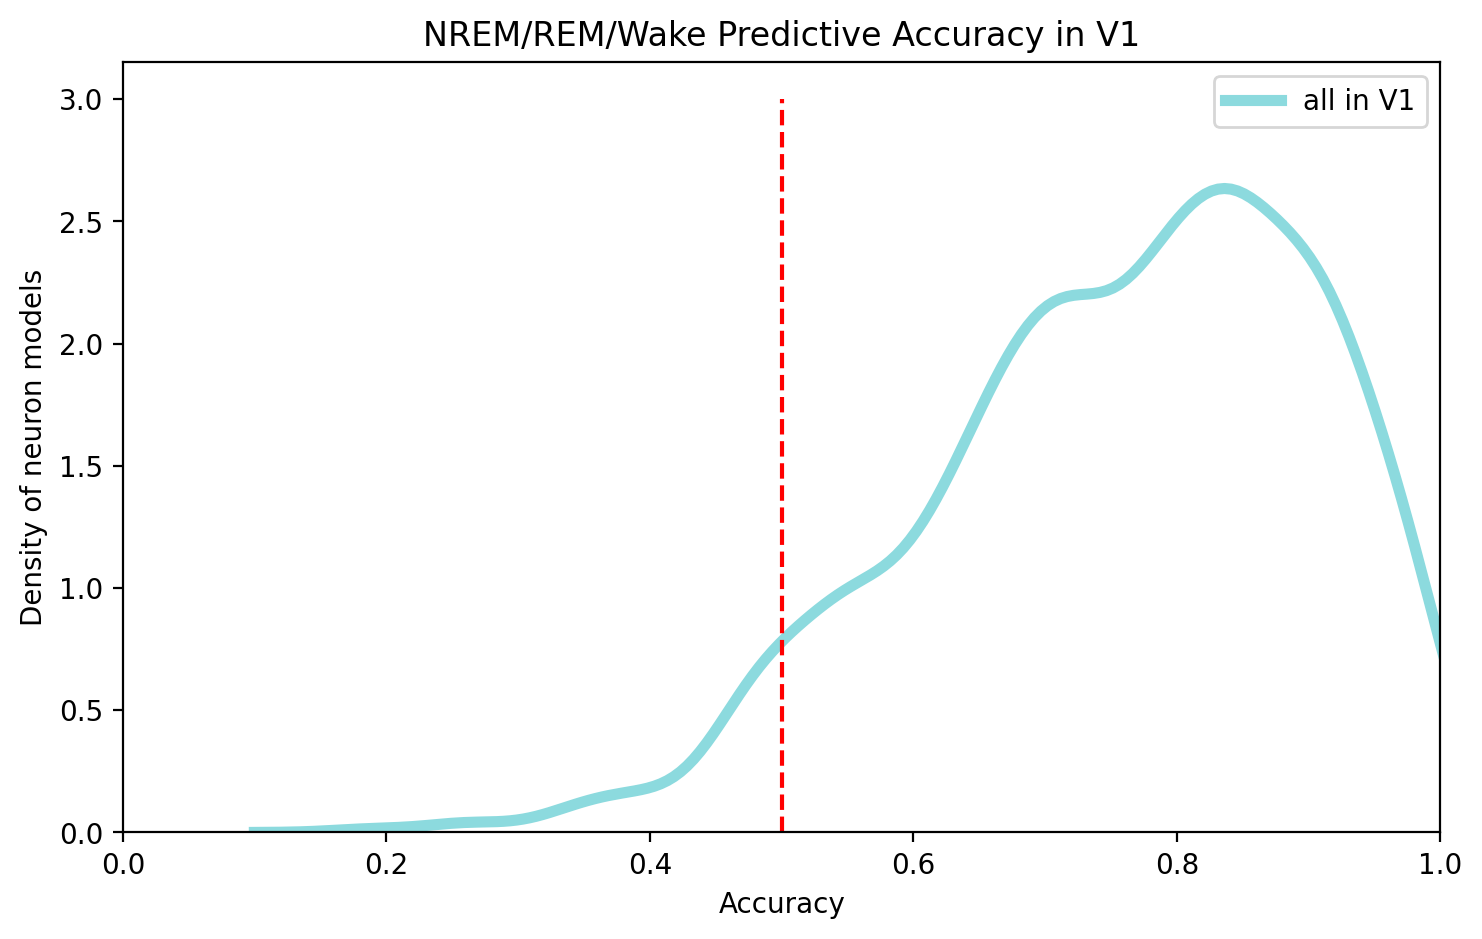

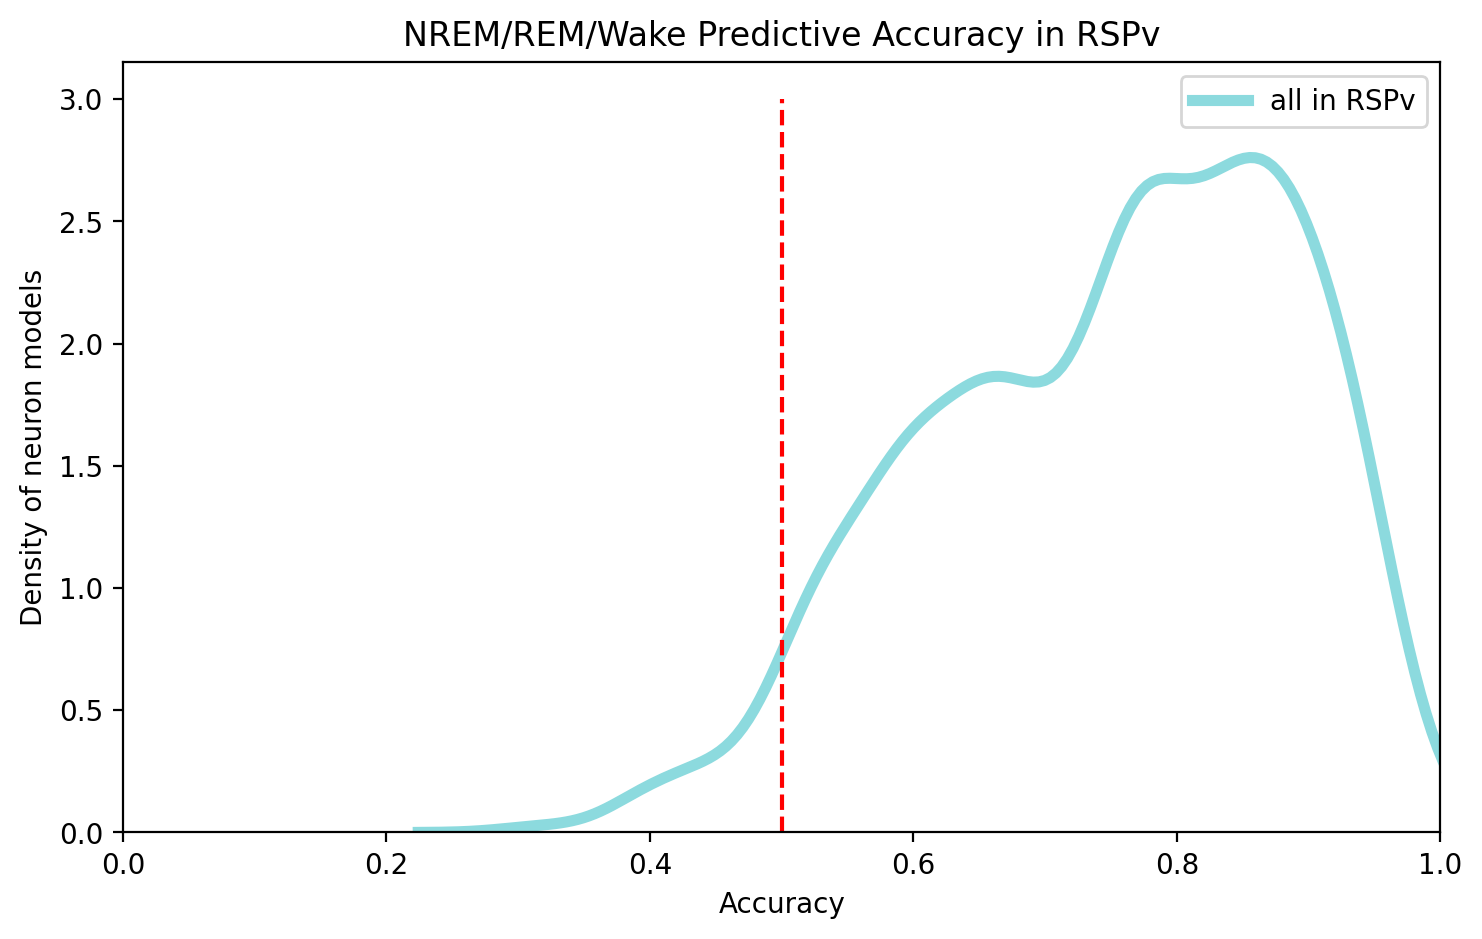

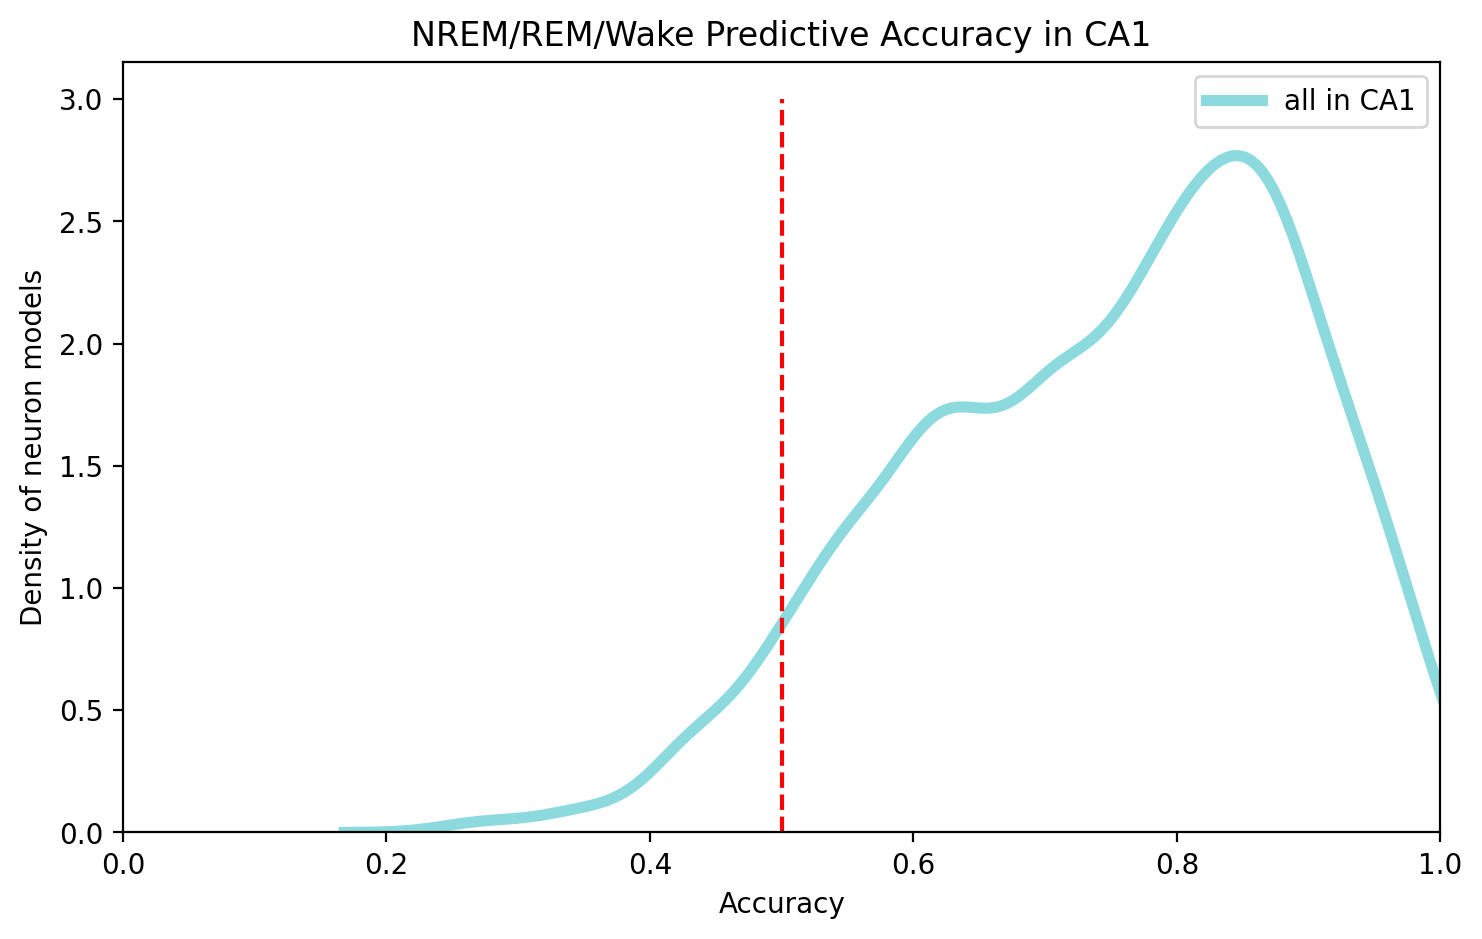

In [94]:
for region in sleep_cond.region.unique():
    fig, ax = plt.subplots(1,1, dpi=200, figsize=(8.5,5))
    get_cm_distrib_hist(sw_cms['LogReg_over'], sleep_cond, f"NREM/REM/Wake Predictive Accuracy in {region}", 
                        norm_size=2, by_geno=True, 
                        by_age=True, kde=True, by_region=True, subset={'region':region},linewidth=4, bw_adjust=0.8
                       )

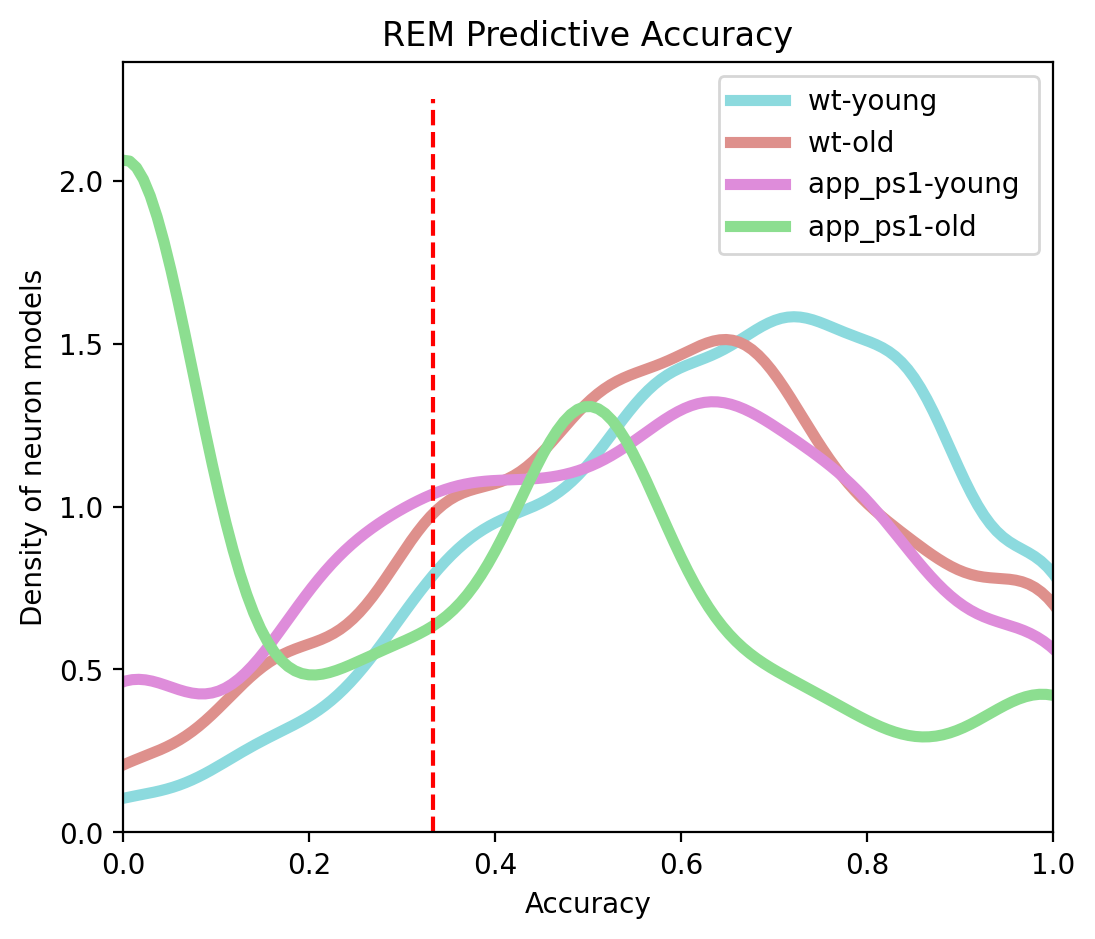

In [130]:
fig, ax = plt.subplots(1,1, dpi=200, figsize=(6,5))
get_cm_distrib_hist(cms['LogReg_over'], sleep_cond, "REM Predictive Accuracy", norm_size=3, by_geno=True, 
                    by_age=True, kde=True, linewidth=4, plot_eval=[lambda x:x[1][1]]
                   )

In [83]:
# with open(f"/media/HlabShare/Toby_work/sleep_indiv_neuron/mlp_cms/full_individual_cell/baseline.pkl", "rb") as f:
#             by_cell_cms = pickle.load(f)

In [85]:
# graphic_train = get_extended_condensed_data(train_scaled)

In [89]:
# merge_accuracy_neuron(by_cell_cms, graphic_train, save=True, name='mlp_acc')

,index,region,cell,animal,celltype,geno,cell_no,age,age_group,state_chunks_nrem,state_chunks_rem,state_chunks_wake,balanced_acc,nrem_acc,rem_acc,wake_acc
1,414,ACad,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,137,40,414,0.658956,0.809524,0.222222,0.945122
4,657,ACad,caf69_358_1228_0_12_1_wt,caf69,RSU,wt,1,358,old,44,28,66,0.611111,0.750000,0.250000,0.833333
7,847,ACad,caf69_358_1228_0_12_2_wt,caf69,RSU,wt,2,358,old,48,31,118,0.704558,0.769231,0.444444,0.900000
10,1107,ACad,caf69_358_1228_0_12_3_wt,caf69,RSU,wt,3,358,old,49,31,181,0.728368,0.769231,0.444444,0.971429
13,1361,ACad,caf69_358_1228_0_12_4_wt,caf69,RSU,wt,4,358,old,47,31,174,0.810185,1.000000,0.444444,0.986111
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12936,1787525,V1,bth100_99_0624_12_24_90_wt,bth100,RSU,wt,90,99,young,54,18,220,0.715493,0.875000,0.333333,0.938144
12939,1787996,V1,bth100_99_0624_12_24_91_wt,bth100,RSU,wt,91,99,young,139,22,399,0.729643,0.931034,0.500000,0.757895
12942,1788356,V1,bth100_99_0624_12_24_92_wt,bth100,RSU,wt,92,99,young,92,18,199,0.549925,0.875000,0.166667,0.608108
12945,1789623,V1,bth100_99_0624_12_24_93_wt,bth100,FS,wt,93,99,young,528,84,1157,0.559407,0.747475,0.111111,0.819635


In [99]:
counts, prop,_,_ = look_at_states_per_grouping(graphic_train, by_animal=True, just_counts=True)

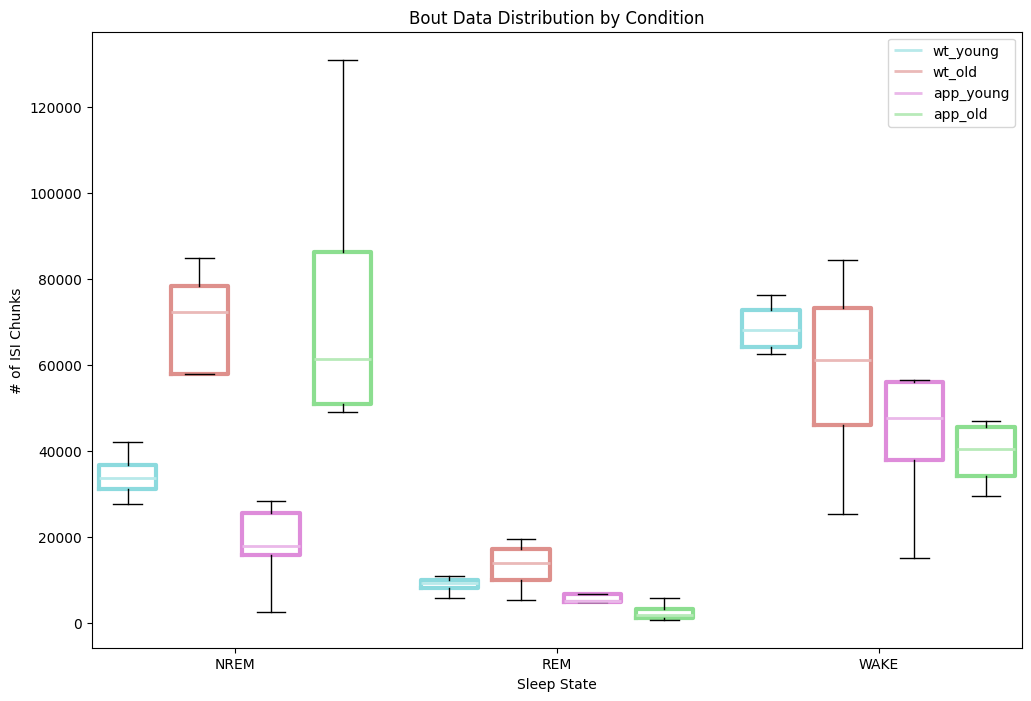

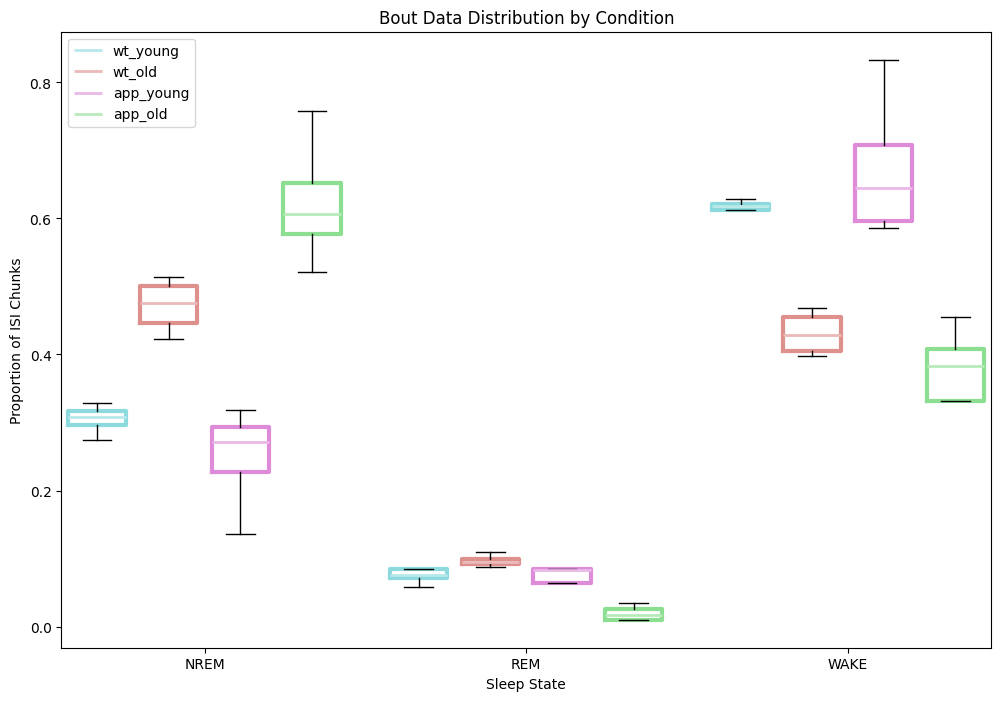

In [105]:
ages = ['young','old']
genos = ['wt', 'app']
split_anim = [[],[],[],[]]
split_props = [[],[],[],[]]
for i, age in enumerate(ages):
    for j, gen in enumerate(genos):
        for key in counts:
            if age in key and gen in key:
                split_anim[i+j*2].append(counts[key])
                split_props[i+j*2].append(prop[key])
by_state = []
by_state_prop = []
for group in split_anim:
    this_ordering =[[],[],[]]
    for anim in group:
        for i in range(3):
            this_ordering[i].append(anim[i])
    by_state.append(this_ordering)
for group in split_props:
    this_ordering =[[],[],[]]
    for anim in group:
        for i in range(3):
            this_ordering[i].append(anim[i])
    by_state_prop.append(this_ordering)
plots, poses = box_whisker(*by_state, inner_d2=False, labels=['NREM', 'REM', 'WAKE'], output=False,
                          color_by_group=False, showfliers=False)
plt.ylabel('# of ISI Chunks')
plt.title('Bout Data Distribution by Condition')
plt.legend([boxplot['medians'][0] for boxplot in plots],['wt_young', 'wt_old','app_young', 'app_old'])
plots, poses = box_whisker(*by_state_prop, inner_d2=False, labels=['NREM', 'REM', 'WAKE'], output=False,
                          color_by_group=False, showfliers=False)
plt.ylabel('Proportion of ISI Chunks')
plt.title('Bout Data Distribution by Condition')
plt.legend([boxplot['medians'][0] for boxplot in plots],['wt_young', 'wt_old','app_young', 'app_old'])

Text(0.5, 0, 'Mouse Group')

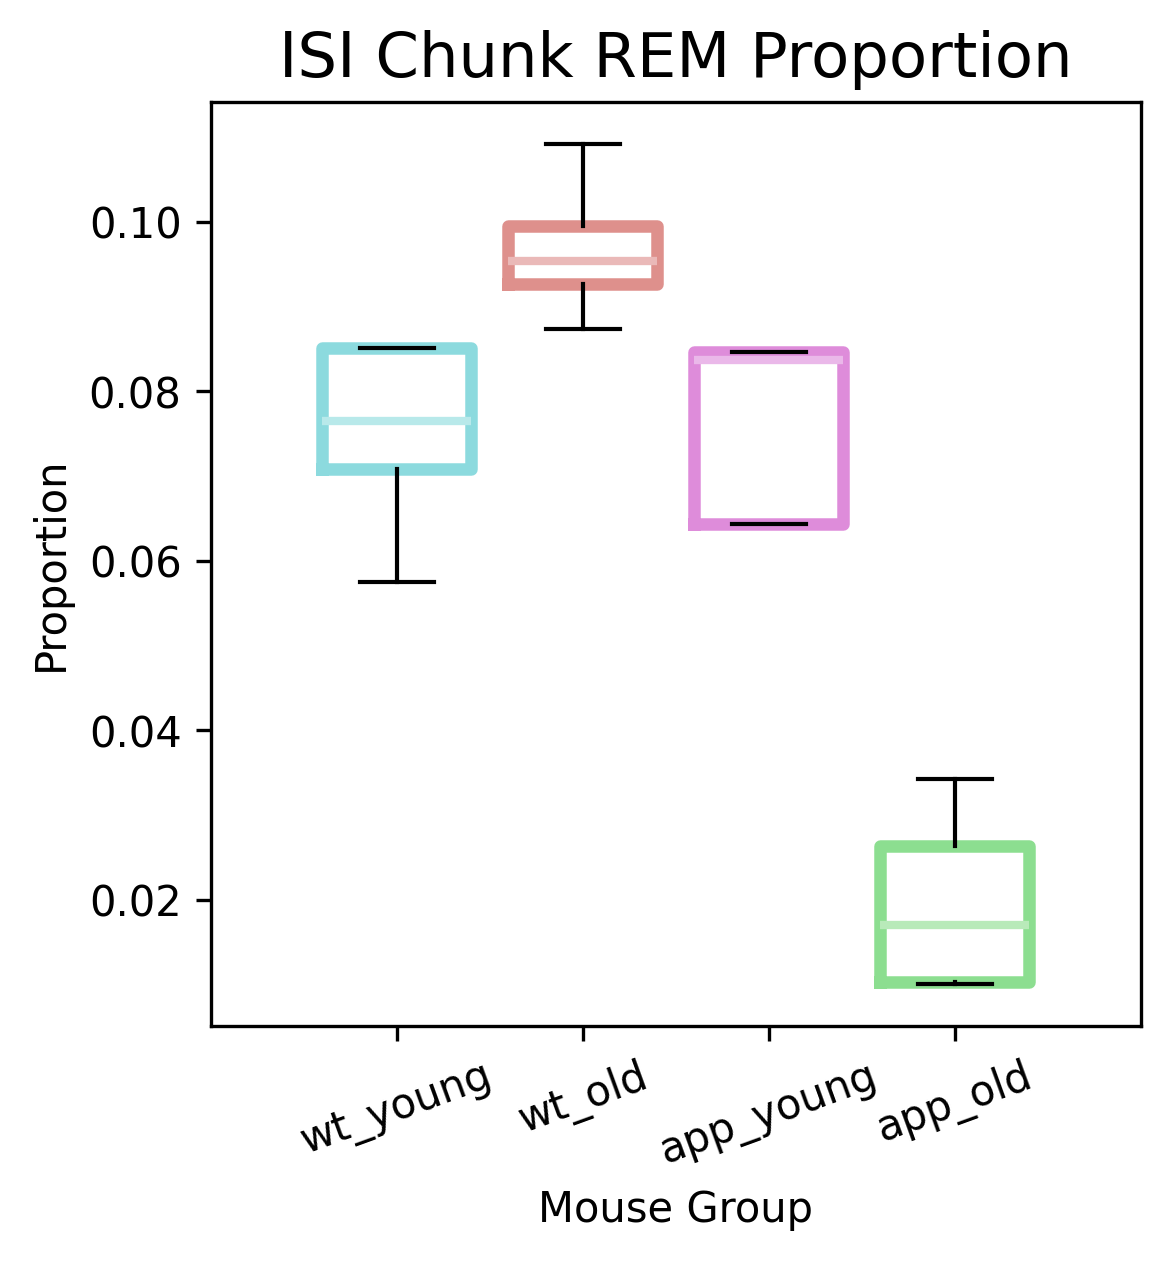

In [124]:
fig, ax = plt.subplots(1,1, figsize=(4,4), dpi=300)
plots, poses = box_whisker([by_state_prop[i][1] for i in range(4)], inner_d2=False, labels=['wt_young', 'wt_old','app_young', 'app_old'], output=False,
                          color_by_group=True, showfliers=False, ax=ax, gap_between_groups=0.5, box_widths=0.4, rotat=20)
plt.title("ISI Chunk REM Proportion", fontsize=15)
plt.ylabel("Proportion")
plt.xlabel("Mouse Group")